**Data Collection**

In [ ]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
import numpy as np
import random
from IPython.core.display import display, HTML
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
!pip -q install requests beautifulsoup4 lxml pandas

# **web scraping  for Najd Village — Menu pages**

In [ ]:
import os, re, mimetypes
from urllib.parse import urljoin, urlparse


URL = "https://najdvillage.com/menu/?lang=en"
HEADERS = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 "
                  "(KHTML, like Gecko) Chrome/124.0.0.0 Safari/537.36",
    "Referer": URL,
}

SAVE_DIR = "images_najd"                      # where images are saved
CSV_OUT  = "najd_menu.csv"  # output CSV


def clean_text(txt: str) -> str:
    return re.sub(r"\s+", " ", (txt or "")).strip()

def canon(s: str) -> str:
    s = clean_text(s).casefold()
    s = s.replace("&amp;", "&")
    s = re.sub(r"\band\b", "&", s)
    s = re.sub(r"\s*&\s*", " & ", s)
    return re.sub(r"\s+", " ", s).strip()

def sanitize_filename(name: str) -> str:
    name = clean_text(name).lower()
    name = re.sub(r"[^\w\-\.]+", "-", name)
    return re.sub(r"-+", "-", name).strip("-") or "image"

def guess_ext(resp, src_url: str) -> str:
    ctype = (resp.headers.get("Content-Type") or "").split(";")[0].strip().lower()
    if ctype.startswith("image/"):
        ext = mimetypes.guess_extension(ctype) or ""
        return ".jpg" if ext == ".jpe" else (ext or ".jpg")
    path_ext = os.path.splitext(urlparse(src_url).path)[1].lower()
    return path_ext if path_ext in {".jpg",".jpeg",".png",".webp",".gif"} else ".jpg"

def unique_path(dirpath: str, basename: str, ext: str) -> str:
    os.makedirs(dirpath, exist_ok=True)
    p = os.path.join(dirpath, f"{basename}{ext}")
    if not os.path.exists(p): return p
    i = 1
    while True:
        q = os.path.join(dirpath, f"{basename}-{i}{ext}")
        if not os.path.exists(q): return q
        i += 1

def download_image(full_url: str, name_hint: str) -> str:
    if not full_url:
        return ""
    try:
        r = requests.get(full_url, headers=HEADERS, timeout=30)
        r.raise_for_status()
        ext = guess_ext(r, full_url)
        base = sanitize_filename(name_hint) or "image"
        out_path = unique_path(SAVE_DIR, base, ext)
        with open(out_path, "wb") as f:
            f.write(r.content)
        return out_path
    except Exception as e:
        print(f"[image fail] {full_url} -> {e}")
        return ""

# categories to KEEP
ALLOWED = {canon(x) for x in [
    "Najdiah Starters",
    "Najdiah Dishes",
    "Main Courses",
    "Magloba & Steam",
    "Najd Dessert",
]}

# --- scrape page HTML ---
r = requests.get(URL, headers=HEADERS, timeout=30)
r.raise_for_status()
soup = BeautifulSoup(r.text, "lxml")

rows = []
for container in soup.select("div.menu-container"):
    heading = container.find_previous("h2", class_="elementor-heading-title")
    category_raw = clean_text(heading.get_text()) if heading else "Uncategorized"
    if canon(category_raw) not in ALLOWED:
        continue

    for item in container.select("div.item"):
        # name (strip embedded price if present)
        name = "N/A"
        h3 = item.select_one("div.item-title > h3")
        if h3:
            price_p = h3.find("p", class_="h-item-price")
            if price_p: price_p.extract()
            name = clean_text(h3.get_text())

        # description
        desc = ""
        desc_el = item.select_one("div.item-excerpt")
        if desc_el:
            for cal in desc_el.select(".archive-page-calories"):
                cal.extract()
            desc = clean_text(desc_el.get_text())

        # image (resolve relative and handle lazy attrs)
        img_el = item.select_one("img.item-img")
        src = ""
        if img_el:
            for attr in ("src", "data-src", "data-lazy-src", "data-original"):
                if img_el.get(attr):
                    src = img_el.get(attr).strip()
                    break
        full_img_url = urljoin(URL, src) if src else ""

        # download image to local file
        local_img_path = download_image(full_img_url, name_hint=name)

        rows.append({
            "Dish Name": name,
            "description": desc,
            "image": local_img_path,
        })

df = pd.DataFrame(rows)
df.to_csv(CSV_OUT, index=False, encoding="utf-8-sig")
print(f"Saved {CSV_OUT} with {len(df)} rows")
df.head(10)

Saved najd_menu.csv with 45 rows


,Dish Name,description,image
0,Jareesh Soup,Jareesh Soup cooked lamp stew & najd spices,images_najd/jareesh-soup.png
1,Lamb Chunk Soup,Lamp chunk soup cooked with fresh ginger,images_najd/lamb-chunk-soup.png
2,Veg & lamb Stew,Lamp stew cooked with mixed vegitables,images_najd/veg-lamb-stew.png
3,Spicy Pepper Salad,"Tomato, green pepper and minced garlic",images_najd/spicy-pepper-salad.png
4,Tomato with Onion Salad,Tomatos and Onion,images_najd/tomato-with-onion-salad.png
5,Taheena Salad,Taheena with yogurt,images_najd/taheena-salad.png
6,Yogurt salad,Yogurt with cucumber and mint,images_najd/yogurt-salad.png
7,Green Salad,"Cucamber, Tomatos and Carrots",images_najd/green-salad.png
8,Meat Sambosa,,images_najd/meat-sambosa.png
9,Cheese Sambosa,,images_najd/cheese-sambosa.png


In [ ]:
# (أ) نزّلي ملف الـ CSV
from google.colab import files
files.download("najd_menu.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# (ب) اضغطي مجلد الصور إلى zip ثم نزّليه
import shutil
shutil.make_archive("images_najd", "zip", "images_najd")  # ينشئ images_najd.zip
from google.colab import files
files.download("images_najd.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>



> **web scraping for Puck Arabia — Arabic Recipes**



In [ ]:
import os, re, json, time, mimetypes
from urllib.parse import urljoin, urlparse, urlunparse


BASE_CATEGORY = "https://www.puckarabia.com/en/recipes/categories/arabic-recipes/"
HEADERS = {
    "User-Agent": ("Mozilla/5.0 (Windows NT 10.0; Win64; x64) "
                   "AppleWebKit/537.36 (KHTML, like Gecko) "
                   "Chrome/124.0.0.0 Safari/537.36"),
    "Referer": BASE_CATEGORY,
}

OUT_CSV  = "puck_recipes.csv"
IMG_DIR  = "images_puck"  # images will be saved here

session = requests.Session()
session.headers.update(HEADERS)

# ---------- Helpers ----------
def get_soup(url, sleep=0.8, tries=3):
    for i in range(tries):
        try:
            r = session.get(url, timeout=30)
            if r.status_code == 200 and r.text:
                time.sleep(sleep)
                return BeautifulSoup(r.text, "lxml")
        except requests.RequestException:
            pass
        time.sleep(1 + i)
    return None

def find_next_page(soup, current_url):
    # 1) <link rel="next">
    link = soup.select_one('link[rel="next"]')
    if link and link.get("href"):
        return urljoin(current_url, link["href"])

    # 2) common anchors
    a = soup.select_one('a.page-numbers.next, a.next, a[aria-label="Next"], nav.pagination a[rel="next"]')
    if a and a.get("href"):
        return urljoin(current_url, a["href"])

    # 3) heuristic /page/N/
    if not re.search(r"/page/\d+/?$", current_url):
        return current_url.rstrip("/") + "/page/2/"
    m = re.search(r"(.*?/page/)(\d+)(/?)$", current_url)
    if m:
        return f"{m.group(1)}{int(m.group(2))+1}/"
    return None

def extract_recipe_links_from_category(soup, page_url):
    links = set()
    for a in soup.select('a[href*="/en/recipes/"]'):
        href = a.get("href")
        if not href:
            continue
        href = urljoin(page_url, href)
        # skip category pages themselves
        if "/en/recipes/categories/" in href:
            continue
        # canonicalize (strip query/fragment)
        p = urlparse(href)
        href_clean = urlunparse((p.scheme, p.netloc, p.path, "", "", "")).rstrip("/")
        links.add(href_clean)
    return sorted(links)

def load_all_jsonld(soup):
    objs = []
    for tag in soup.select('script[type="application/ld+json"]'):
        raw = (tag.string or tag.text or "").strip()
        if not raw:
            continue
        for fixer in (lambda x: x,
                      lambda x: re.sub(r",\s*}", "}", x),
                      lambda x: re.sub(r",\s*]", "]", x)):
            try:
                data = json.loads(fixer(raw))
                if isinstance(data, dict):
                    objs.append(data)
                elif isinstance(data, list):
                    objs.extend(data)
                break
            except Exception:
                continue
    # flatten @graph
    out = []
    for o in objs:
        if isinstance(o, dict) and "@graph" in o and isinstance(o["@graph"], list):
            out.extend(o["@graph"])
        else:
            out.append(o)
    return out

def first_non_empty(*vals):
    for v in vals:
        if isinstance(v, str) and v.strip():
            return v.strip()
    return ""

def to_text_list(x):
    if isinstance(x, list):
        return [str(i).strip() for i in x if str(i).strip()]
    if isinstance(x, str) and x.strip():
        return [x.strip()]
    return []

def extract_recipe_from_jsonld_min(soup):
    # Only keep name, description, image_url, ingredients
    desired = {
        "name": "",
        "description": "",
        "image_url": "",
        "ingredients": [],
    }
    for o in load_all_jsonld(soup):
        t = o.get("@type")
        types = [t] if isinstance(t, str) else (t or [])
        types = [str(i).lower() for i in types]
        if "recipe" in types:
            desired["name"] = first_non_empty(o.get("name", ""))
            desired["description"] = first_non_empty(o.get("description", ""))

            img = o.get("image", "")
            if isinstance(img, list) and img:
                desired["image_url"] = str(img[0])
            elif isinstance(img, dict):
                desired["image_url"] = first_non_empty(img.get("url",""), img.get("@id",""))
            elif isinstance(img, str):
                desired["image_url"] = img

            desired["ingredients"] = to_text_list(o.get("recipeIngredient", []))
            break
    return desired

def fallback_extract_min(soup):
    name = ""
    h1 = soup.select_one("h1")
    if h1: name = h1.get_text(strip=True)

    desc = ""
    meta = soup.select_one('meta[name="description"]')
    if meta and meta.get("content"): desc = meta["content"].strip()

    ogimg = ""
    mi = soup.select_one('meta[property="og:image"], meta[name="og:image"]')
    if mi and mi.get("content"): ogimg = mi["content"].strip()

    ingredients = [li.get_text(" ", strip=True) for li in soup.select(".ingredients li, .ingredient, li[class*='ingredient']")]
    if not ingredients:
        ingredients = [li.get_text(" ", strip=True) for li in soup.select("ul li") if "ingredient" in (li.get("class") or [])]

    return {
        "name": name,
        "description": desc,
        "image_url": ogimg,
        "ingredients": ingredients,
    }

# ---------- Image download ----------
def sanitize_filename(name: str) -> str:
    name = re.sub(r"\s+", " ", (name or "")).strip().lower()
    # keep Arabic letters too
    name = re.sub(r"[^\w\-\.\u0600-\u06FF]+", "-", name)
    return re.sub(r"-+", "-", name).strip("-") or "image"

def guess_ext(resp, src_url: str) -> str:
    ctype = (resp.headers.get("Content-Type") or "").split(";")[0].strip().lower()
    if ctype.startswith("image/"):
        ext = mimetypes.guess_extension(ctype) or ""
        return ".jpg" if ext == ".jpe" else (ext or ".jpg")
    # fallback to URL path
    path = urlparse(src_url).path
    ext = os.path.splitext(path)[1].lower()
    return ext if ext in {".jpg",".jpeg",".png",".webp",".gif"} else ".jpg"

def unique_path(dirpath: str, basename: str, ext: str) -> str:
    os.makedirs(dirpath, exist_ok=True)
    p = os.path.join(dirpath, f"{basename}{ext}")
    if not os.path.exists(p):
        return p
    i = 1
    while True:
        q = os.path.join(dirpath, f"{basename}-{i}{ext}")
        if not os.path.exists(q):
            return q
        i += 1

def download_image(image_url: str, name_hint: str, referer: str) -> str:
    """Download image and return LOCAL path ('' on failure)."""
    if not image_url:
        return ""
    try:
        r = session.get(image_url, headers={"Referer": referer, **HEADERS}, timeout=30)
        r.raise_for_status()
        ext = guess_ext(r, image_url)
        base = sanitize_filename(name_hint)
        out_path = unique_path(IMG_DIR, base, ext)
        with open(out_path, "wb") as f:
            f.write(r.content)
        return out_path
    except Exception:
        return ""

# ---------- Scraper ----------
def scrape_category_min(base_url=BASE_CATEGORY, max_pages=50):
    seen, pages = set(), []
    url = base_url.rstrip("/") + "/"

    # Walk category pagination
    for _ in range(max_pages):
        if url in seen:
            break
        soup = get_soup(url)
        if not soup:
            break
        pages.append((url, soup))
        seen.add(url)

        nxt = find_next_page(soup, url)
        if not nxt or nxt in seen:
            break
        # quick check next page exists
        r = session.get(nxt, timeout=15)
        if r.status_code != 200 or not r.text:
            break
        url = nxt

    # Collect all recipe URLs found on each page
    recipe_urls = set()
    for page_url, soup in pages:
        for link in extract_recipe_links_from_category(soup, page_url):
            recipe_urls.add(link)

    # Visit each recipe page and extract fields + download image
    rows = []
    for ru in sorted(recipe_urls):
        rsoup = get_soup(ru)
        if not rsoup:
            continue

        item = extract_recipe_from_jsonld_min(rsoup)
        if not item.get("name"):
            item = fallback_extract_min(rsoup)

        #  image download locally
        image_url = item.get("image_url", "")
        if image_url:
            image_url = urljoin(ru, image_url)

        local_image_path = download_image(image_url, item.get("name","image"), referer=ru)

        rows.append({
            "Dish Name": item.get("name","").strip(),
            "description": item.get("description","").strip(),
            "image": local_image_path,
            "recipe": " | ".join(item.get("ingredients", [])),
        })

    return rows

# ---------- Run ----------
if __name__ == "__main__":
    rows = scrape_category_min(BASE_CATEGORY, max_pages=50)
    df = pd.DataFrame(rows, columns=["Dish Name","description","image","recipe"])
    df.to_csv(OUT_CSV, index=False, encoding="utf-8-sig")
    print(f"Saved {OUT_CSV} with {len(df)} rows; images saved under '{IMG_DIR}/'")
    print(df.head(10))


Saved puck_recipes.csv with 94 rows; images saved under 'images_puck/'
                                           Dish Name  \
0                    YOU MAKE IT SPECIALPuck Recipes   
1                                     Aish Al Saraya   
2  Arabic bread with cheese, honey, pomegranate s...   
3  Arabic bread with cream cheese, chicken strips...   
4  Arabic bread with cream cheese, minced meat, c...   
5                           Arabic Breakfast Platter   
6  Arabic Breakfast Platter with Less Salt Cream ...   
7                               Arabic Cream Pudding   
8      Arabic Spiced Meatballs In Tomato Cream Sauce   
9           Arayes (Middle Easten Meat Stuffed Pita)   

                                         description  \
0                                                      
1  Aish Al Saraya is an ideal dessert to serve at...   
2  This simple and fast recipe combines the richn...   
3  This Arabic bread with cream cheese, chicken s...   
4  Rich cream cheese combines pe

In [ ]:
# اضغطي مجلد الصور إلى zip ثم نزّليه
import shutil
shutil.make_archive("images_puck", "zip", "images_puck")  # يولّد images_puck.zip
from google.colab import files
files.download("images_puck.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>



>  **merge puck and najd**



In [ ]:
import pandas as pd

PUCK_CSV = "puck_recipes.csv"
NAJD_CSV = "najd_menu.csv"
OUT_CSV  = "Arabic_food.csv"

def load_and_standardize(path: str) -> pd.DataFrame:
    df = pd.read_csv(path)

    # name
    name_col = next((c for c in ["Dish Name", "dish name", "name", "Name"] if c in df.columns), None)
    if name_col is None:
        raise ValueError(f"No name column found in {path}")

    # description
    desc_col = next((c for c in ["description", "desc", "summary"] if c in df.columns), None)
    if desc_col is None:
        df["description"] = ""
        desc_col = "description"

    # recipe
    recipe_col = next((c for c in ["recipe", "recipes", "instructions", "method", "steps", "preparation"]
                       if c in df.columns), None)
    if recipe_col is None:
        df["recipe"] = ""
        recipe_col = "recipe"

    # image
    img_col = next((c for c in ["image", "image_path", "image_url", "img", "picture", "photo"]
                    if c in df.columns), None)
    if img_col is None:
        df["image"] = ""
        img_col = "image"

    out = df[[name_col, desc_col, recipe_col, img_col]].copy()
    out.columns = ["Dish Name", "description", "recipe", "image"]  # unify
    return out

puck = load_and_standardize(PUCK_CSV)
najd = load_and_standardize(NAJD_CSV)

merged = pd.concat([puck, najd], ignore_index=True)


merged.to_csv(OUT_CSV, index=False, encoding="utf-8-sig")
print(f"Saved {OUT_CSV} with {len(merged)} rows")
print(merged.head(10))


Saved Arabic_food.csv with 139 rows
                                           Dish Name  \
0                    YOU MAKE IT SPECIALPuck Recipes   
1                                     Aish Al Saraya   
2  Arabic bread with cheese, honey, pomegranate s...   
3  Arabic bread with cream cheese, chicken strips...   
4  Arabic bread with cream cheese, minced meat, c...   
5                           Arabic Breakfast Platter   
6  Arabic Breakfast Platter with Less Salt Cream ...   
7                               Arabic Cream Pudding   
8      Arabic Spiced Meatballs In Tomato Cream Sauce   
9           Arayes (Middle Easten Meat Stuffed Pita)   

                                         description  \
0                                                NaN   
1  Aish Al Saraya is an ideal dessert to serve at...   
2  This simple and fast recipe combines the richn...   
3  This Arabic bread with cream cheese, chicken s...   
4  Rich cream cheese combines perfectly with the ...   
5  Puck Cre



> **Handle missing data via API Calculates protein, calories, carbs and fat**



In [ ]:
import os, time, json, math, re, requests


CSV_IN  = "Arabic_food.csv"
CSV_OUT = "Arabic_food_NUTRITIONI.csv"

NUTRITIONIX_APP_ID  = "c242359d"
NUTRITIONIX_API_KEY = "3e2232dd07773d9d2f257f4a60f979f4"

API_URL = "https://trackapi.nutritionix.com/v2/natural/nutrients"
HEADERS = {
    "x-app-id": NUTRITIONIX_APP_ID,
    "x-app-key": NUTRITIONIX_API_KEY,
    "Content-Type": "application/json"
}


def _s(x) -> str:
    """Safe trimmed string; NaN/None -> ''."""
    try:
        if x is None: return ""
        if isinstance(x, float) and math.isnan(x): return ""
    except Exception:
        pass
    return str(x).strip()

def build_query(dish_name, recipe, description) -> str:
    """
    Build one 'natural language' query using your columns:
    - dish_name -> 'Dish Name'
    - recipe    -> 'recipes' (ingredients text)
    - description -> 'description'
    """
    name = _s(dish_name)
    rec  = _s(recipe)
    desc = _s(description)

    # split recipe text on |, comma, semicolon, or newline to get ingredient list
    rec_list = [p.strip() for p in re.split(r"\||,|;|\n", rec) if p.strip()]
    rec_txt  = ", ".join(rec_list)

    if rec_txt and name:
        q = f"1 serving {name}. Ingredients: {rec_txt}."
    elif name and desc:
        q = f"1 serving {name}. {desc}"
    elif name:
        q = f"1 serving {name}"
    elif rec_txt:
        q = f"1 serving dish with {rec_txt}"
    else:
        q = desc or "1 serving dish"
    return q

def call_nutritionix(query: str, retries: int = 3, backoff: float = 1.0):
    """
    Call Nutritionix and return summed macros.
    Returns dict with protein_g, carbs_g, fat_g, calories_kcal (0s if not parsed).
    """
    payload = {"query": query}
    for i in range(retries):
        try:
            r = requests.post(API_URL, headers=HEADERS, json=payload, timeout=30)
            if r.status_code == 200:
                data = r.json() or {}
                foods = data.get("foods", []) or []
                p = c = f = kcal = 0.0
                for it in foods:
                    p    += float(it.get("nf_protein", 0) or 0)
                    c    += float(it.get("nf_total_carbohydrate", 0) or 0)
                    f    += float(it.get("nf_total_fat", 0) or 0)
                    kcal += float(it.get("nf_calories", 0) or 0)
                return {
                    "calories_kcal": int(round(kcal)),
                    "protein_g": round(p, 1),
                    "carbs_g":   round(c, 1),
                    "fat_g":     round(f, 1),
                }
            elif r.status_code in (408, 429, 500, 502, 503, 504):
                time.sleep(backoff * (i + 1))  # retryable
            else:
                # non-retryable or unparsed
                return {"calories_kcal":0, "protein_g":0.0, "carbs_g":0.0, "fat_g":0.0}
        except requests.RequestException:
            time.sleep(backoff * (i + 1))
    return {"calories_kcal":0, "protein_g":0.0, "carbs_g":0.0, "fat_g":0.0}

# ========= LOAD =========
df = pd.read_csv(CSV_IN)

# Ensure expected columns exist (Dish Name, description, recipes, image)
for col in ["Dish Name", "description", "recipes", "image"]:
    if col not in df.columns:
        df[col] = ""
df[["Dish Name", "description", "recipes", "image"]] = (
    df[["Dish Name", "description", "recipes", "image"]].fillna("")
)

results = []
cache = {}

for _, row in df.iterrows():
    q = build_query(row.get("Dish Name",""), row.get("recipes",""), row.get("description",""))
    if q in cache:
        macros = cache[q]
    else:
        macros = call_nutritionix(q)
        cache[q] = macros
    results.append(macros)
    time.sleep(0.4)

macros_df = pd.DataFrame(results)

# ========= FINAL FILE (no description/recipes) =========
out = pd.concat([df[["Dish Name","image"]], macros_df], axis=1)
out.to_csv(CSV_OUT, index=False, encoding="utf-8-sig")
print(f"Saved {CSV_OUT} with {len(out)} rows")
print(out.head(10))


Saved Arabic_food_NUTRITIONI.csv with 139 rows
                                           Dish Name  \
0                    YOU MAKE IT SPECIALPuck Recipes   
1                                     Aish Al Saraya   
2  Arabic bread with cheese, honey, pomegranate s...   
3  Arabic bread with cream cheese, chicken strips...   
4  Arabic bread with cream cheese, minced meat, c...   
5                           Arabic Breakfast Platter   
6  Arabic Breakfast Platter with Less Salt Cream ...   
7                               Arabic Cream Pudding   
8      Arabic Spiced Meatballs In Tomato Cream Sauce   
9           Arayes (Middle Easten Meat Stuffed Pita)   

                                               image  calories_kcal  \
0                                                                 0   
1                     images_puck/aish-al-saraya.jpg            671   
2  images_puck/arabic-bread-with-cheese-honey-pom...            840   
3  images_puck/arabic-bread-with-cream-cheese-chi...

# **web scraping for butfirstchai**

In [ ]:
import os, re, time, json, mimetypes
from urllib.parse import urljoin, urlparse

START_URL   = "https://butfirstchai.com/category/middle-eastern-recipes/"
UA = ("Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 "
      "KHTML, like Gecko) Chrome/124.0.0.0 Safari/537.36")

OUT_CSV     = "butfirstchai_arabic_recipes.csv"
IMG_DIR     = "images_butfirstchai"
DEBUG       = False

# Keep ONLY Arabic dishes by simple keyword pass? (False = keep all)
ARABIC_ONLY = False
ARABIC_KEYWORDS = [
    "kabsa","kabsah","margoog","margoug","matazeez","saleek","jareesh","harees",
    "mohlabia","muhalabia","mahalabia","maqluba","magluba","ouzi","kunafa","kanafeh",
    "basbousa","qatayef","qishta","labneh","zaatar","shawarma","fatteh","falafel",
    "manakeesh","manakish","sambosa","samboosa","kofta","fatayer","umm ali",
    "maamoul","muhammara","fattoush","hummus","kebab","arayes","sabeeb",
    "qamar al-deen","qamar al deen"
]

# Titles/sections to DROP outright
TITLE_BLOCKLIST_PATTERNS = [
    r"\brecipes?\b$",
    r"\babout( me)?\b",
    r"\bprivacy policy\b",
    r"\bdisclosure\b|\bterms\b|\bcontact\b|\bsubscribe\b|\bnewsletter\b",
    r"homemade family[- ]favorite indian and arabic recipes",
    r"\bsearch results\b",
]

session = requests.Session()
session.headers.update({"User-Agent": UA, "Referer": START_URL})

# ================== HELPERS ==================
def clean(s):
    return re.sub(r"\s+", " ", (s or "")).strip()

def log(*args):
    if DEBUG: print(*args)

def get_soup(url, tries=3, sleep=0.5):
    for i in range(tries):
        try:
            r = session.get(url, timeout=30)
            if r.status_code == 200 and r.text:
                time.sleep(sleep)
                return BeautifulSoup(r.text, "lxml")
            log(f"[GET {r.status_code}] {url}")
        except requests.RequestException as e:
            log(f"[GET err] {url} -> {e}")
        time.sleep(0.6*(i+1))
    return None

def valid_post_href(href: str) -> bool:
    if not href or not href.startswith("http"):
        return False
    netloc = urlparse(href).netloc
    if "butfirstchai.com" not in netloc:
        return False
    badbits = ("/category/", "/tag/", "/page/", "/feed", "?replytocom=")
    if any(b in href for b in badbits):
        return False
    if href.endswith((".jpg",".jpeg",".png",".webp",".gif")):
        return False
    return True

def extract_post_links(soup, page_url):
    links = set()
    selectors = [
        "main article h2.entry-title a",
        "article h2.entry-title a",
        "article header a[rel='bookmark']",
    ]
    for sel in selectors:
        for a in soup.select(sel):
            href = a.get("href")
            if valid_post_href(href):
                links.add(urljoin(page_url, href))
    if not links:
        for a in soup.select("a[href]"):
            href = urljoin(page_url, a.get("href"))
            if valid_post_href(href):
                links.add(href)
    links = sorted(links)
    log(f"  -> found {len(links)} post links")
    return links

def find_next_page(soup, current_url):
    link = soup.select_one('link[rel="next"]')
    if link and link.get("href"):
        return urljoin(current_url, link["href"])
    for a in soup.select("a.next, a[rel='next'], .nav-links a.next, .pagination a.next, a.page-numbers.next"):
        if a.get("href"):
            return urljoin(current_url, a.get("href"))
    m = re.search(r"/page/(\d+)/?$", current_url)
    if not m:
        return current_url.rstrip("/") + "/page/2/"
    n = int(m.group(1)) + 1
    return re.sub(r"/page/\d+/?$", f"/page/{n}/", current_url)

def blocked_title(name: str) -> bool:
    n = (name or "").strip().lower()
    return any(re.search(pat, n, flags=re.I) for pat in TITLE_BLOCKLIST_PATTERNS)

def is_arabic_dish(name: str) -> bool:
    n = (name or "").lower()
    return any(k in n for k in ARABIC_KEYWORDS)

def load_all_jsonld(soup):
    objs = []
    for tag in soup.select('script[type="application/ld+json"]'):
        raw = (tag.string or tag.text or "").strip()
        if not raw:
            continue
        for fixer in (lambda x: x,
                      lambda x: re.sub(r",\s*}", "}", x),
                      lambda x: re.sub(r",\s*]", "]", x)):
            try:
                data = json.loads(fixer(raw))
                objs.extend(data if isinstance(data, list) else [data])
                break
            except Exception:
                continue
    flat = []
    for o in objs:
        if isinstance(o, dict) and isinstance(o.get("@graph"), list):
            flat.extend(o["@graph"])
        else:
            flat.append(o)
    return flat

_num = re.compile(r"(-?\d+(?:\.\d+)?)")
def num_from_text(x):
    if not x: return 0.0
    m = _num.search(str(x))
    return float(m.group(1)) if m else 0.0

def parse_nutrition_from_jsonld_objs(objs):
    """Return name, image_url, calories, protein, carbs, fat from a Recipe object if present."""
    name = image = ""
    kcal = p = c = f = 0.0
    for o in objs:
        t = o.get("@type")
        types = [t] if isinstance(t, str) else (t or [])
        types = [str(i).lower() for i in types]
        if "recipe" in types:
            name = clean(o.get("name", "")) or name
            img = o.get("image", "")
            if isinstance(img, list) and img:
                image = img[0]
            elif isinstance(img, dict):
                image = img.get("url") or img.get("@id") or ""
            elif isinstance(img, str):
                image = img
            nut = o.get("nutrition", {}) or {}
            kcal = kcal or num_from_text(nut.get("calories"))
            p    = p    or num_from_text(nut.get("proteinContent"))
            c    = c    or num_from_text(nut.get("carbohydrateContent"))
            f    = f    or num_from_text(nut.get("fatContent"))
            break
    return name, image, kcal, p, c, f

def parse_nutrition_fallbacks(soup):
    """WP Recipe Maker blocks or generic table text."""
    def try_val(cls):
        el = soup.select_one(f".wprm-nutrition-{cls} .wprm-nutrition-value")
        return num_from_text(el.get_text(" ", strip=True)) if el else 0.0

    kcal = try_val("calories") or num_from_text(
        soup.select_one(".wprm-nutrition-calories")
        and soup.select_one(".wprm-nutrition-calories").get_text(" ", strip=True)
    )
    p    = try_val("protein")
    c    = try_val("carbohydrates")
    f    = try_val("fat")

    if not any([kcal, p, c, f]):
        for row in soup.select("table tr, .wprm-nutrition-label-container *"):
            txt = row.get_text(" ", strip=True).lower()
            if "calor" in txt:   kcal = kcal or num_from_text(txt)
            if "protein" in txt: p    = p    or num_from_text(txt)
            if "carb" in txt:    c    = c    or num_from_text(txt)
            if "fat" in txt:     f    = f    or num_from_text(txt)

    return int(round(kcal or 0)), round(p or 0,1), round(c or 0,1), round(f or 0,1)

# ------ normalize titles (Mahjouba | Algerian Semolina Crepes -> Mahjouba)
DESCRIPTOR_KEYWORDS = (
    "recipe", "how to", "with", "without", "style", "authentic", "easy",
    "best", "traditional", "homemade", "semolina", "crepes", "step by step",
    "middle eastern", "arabic", "algerian", "moroccan", "lebanese", "egyptian",
    "saudi", "syrian", "iraqi", "gulf", "emirati", "jordanian", "palestinian",
    "yemeni", "tunisian", "kuwaiti", "bahraini", "omani"
)

def simplify_dish_name(name: str) -> str:
    n = clean(name)
    n = re.sub(r"\s*[\(\[\{].*?[\)\]\}]\s*", " ", n)             # remove (...) / [...] / {...}
    n = re.split(r"\s*(?:\|+|:+)\s*", n)[0]                      # split on | or :
    if re.search(r"\s[-–—]\s", n):                               # split on dash if right looks like descriptor
        left, right = re.split(r"\s[-–—]\s", n, maxsplit=1)
        if any(k in right.lower() for k in DESCRIPTOR_KEYWORDS):
            n = left
    n = re.sub(r"\brecipe\b.*$", "", n, flags=re.I)              # trim trailing 'recipe ...'
    n = re.sub(r"\s+", " ", n).strip(" -–—|: ").strip()
    return n or name

def slug(s: str) -> str:
    return re.sub(r"[^a-z0-9]+", "-", clean(s).lower()).strip("-")

def download_image(url, name_hint):
    """Download an image and return the local file path. If fail or no URL -> ''."""
    if not url:
        return ""
    try:
        os.makedirs(IMG_DIR, exist_ok=True)
        r = session.get(url, timeout=30)
        r.raise_for_status()
        ctype = (r.headers.get("Content-Type") or "").split(";")[0].lower()
        ext = mimetypes.guess_extension(ctype) or ".jpg"
        if ext == ".jpe": ext = ".jpg"
        base = re.sub(r"[^\w\-\.\u0600-\u06FF]+", "-", clean(name_hint).lower()) or "image"
        path = os.path.join(IMG_DIR, f"{base}{ext}")
        i = 1
        while os.path.exists(path):
            path = os.path.join(IMG_DIR, f"{base}-{i}{ext}")
            i += 1
        with open(path, "wb") as f:
            f.write(r.content)
        return path
    except Exception as e:
        log(f"[image fail] {url} -> {e}")
        return ""

# ================== PARSERS ==================
def parse_recipe_page(url):
    soup = get_soup(url)
    if not soup:
        return None

    # 1) JSON-LD first
    name, img_url, kcal, p, c, f = parse_nutrition_from_jsonld_objs(load_all_jsonld(soup))

    # 2) Fallbacks for name/image
    if not name:
        h1 = soup.select_one("h1.entry-title, h1")
        if h1: name = clean(h1.get_text())
    if not img_url:
        og = soup.select_one('meta[property="og:image"], meta[name="og:image"]')
        if og and og.get("content"):
            img_url = og["content"].strip()
    if img_url:
        img_url = urljoin(url, img_url)

    kcal2, p2, c2, f2 = parse_nutrition_fallbacks(soup)
    kcal = int(kcal) if kcal else int(kcal2)
    p    = round(p or p2, 1)
    c    = round(c or c2, 1)
    f    = round(f or f2, 1)

    # normalize title (e.g., remove country/SEO tails)
    name = simplify_dish_name(name)

    if not name or blocked_title(name):
        return None
    if ARABIC_ONLY and not is_arabic_dish(name):
        return None
    # If absolutely no nutrition found, drop (prevents “Recipes” noise rows)
    if kcal == 0 and p == 0 and c == 0 and f == 0:
        return None

    #  download image now and store LOCAL PATH
    image_path = download_image(img_url, name)

    return {
        "Dish Name": name,
        "protein_g": p,
        "carbs_g":   c,
        "fat_g":     f,
        "calories_kcal": kcal,
        "image": image_path,
    }

# ================== MAIN SCRAPER ==================
def scrape_butfirstchai(max_pages=40, delay=0.4):
    rows = []
    url = START_URL.rstrip("/") + "/"
    seen_pages = set()

    for _ in range(max_pages):
        if url in seen_pages:
            break
        soup = get_soup(url)
        if not soup:
            break
        seen_pages.add(url)

        links = extract_post_links(soup, url)

        for link in links:
            rec = parse_recipe_page(link)
            if not rec:
                continue
            rows.append(rec)
            time.sleep(delay)

        nxt = find_next_page(soup, url)
        if not nxt:
            log("No next page; stopping.")
            break
        # sanity check next page
        r = session.get(nxt, timeout=15)
        if r.status_code != 200 or not r.text:
            log(f"Next page not reachable ({r.status_code}); stopping.")
            break
        url = nxt

    # If nothing, still write an empty CSV with correct headers
    if not rows:
        pd.DataFrame(columns=["Dish Name","protein_g","carbs_g","fat_g","calories_kcal","image"]).to_csv(
            OUT_CSV, index=False, encoding="utf-8-sig"
        )
        print(f"Saved {OUT_CSV} with 0 recipes")
        return

    df = pd.DataFrame(rows)

    # De-duplicate by simplified dish name only
    df["dish_slug"] = df["Dish Name"].apply(slug)
    df = df.drop_duplicates(subset=["dish_slug"], keep="first").drop(columns=["dish_slug"])

    # Final columns & save
    df = df[["Dish Name","protein_g","carbs_g","fat_g","calories_kcal","image"]]
    df.to_csv(OUT_CSV, index=False, encoding="utf-8-sig")
    print(f"Saved {OUT_CSV} with {len(df)} recipes; images saved under '{IMG_DIR}/'")

if __name__ == "__main__":
    scrape_butfirstchai(max_pages=40, delay=0.4)


Saved butfirstchai_arabic_recipes.csv with 68 recipes; images saved under 'images_butfirstchai/'


In [ ]:
# اضغطي مجلد الصور إلى ZIP ثم نزّليه
import shutil
shutil.make_archive("images_butfirstchai", "zip", "images_butfirstchai")  # يولّد images_butfirstchai.zip
from google.colab import files
files.download("images_butfirstchai.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# **merge with other**

In [ ]:

SCRAPED = "butfirstchai_arabic_recipes.csv"
OTHER   = "Arabic_food_NUTRITIONI.csv"
OUT     = "Arabic_food_MERGED.csv"

# Read both files
df1 = pd.read_csv(SCRAPED, encoding="utf-8-sig")
df2 = pd.read_csv(OTHER,   encoding="utf-8-sig")

#  same column order as the first file:
df2 = df2[df1.columns.tolist()]

# Merge and save
merged = pd.concat([df1, df2], ignore_index=True)
merged.to_csv(OUT, index=False, encoding="utf-8-sig")

print(f"Saved {OUT} with {len(merged)} rows")
print(merged.head())



Saved Arabic_food_MERGED.csv with 207 rows
                         Dish Name  protein_g  carbs_g  fat_g  calories_kcal  \
0                     Aqras Helweh        2.1     22.2    6.0            147   
1                           Arayes        4.8      5.5    3.3             71   
2                     Baba Ganoush        2.6     13.1    7.7            120   
3  Homemade Gulf Baharat Spice Mix        1.1      5.3    1.1             26   
4        Bahraini Chicken Machboos       34.0     52.4   31.0            632   

                                               image  
0               images_butfirstchai/aqras-helweh.jpg  
1                     images_butfirstchai/arayes.jpg  
2               images_butfirstchai/baba-ganoush.jpg  
3  images_butfirstchai/homemade-gulf-baharat-spic...  
4  images_butfirstchai/bahraini-chicken-machboos.jpg  


# **Phase 2:**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, MinMaxScaler
import os
from PIL import Image
from tqdm import tqdm

## **Data Processing & Cleaning**

In [ ]:
#Load the dataset
df = pd.read_csv('Arabic_food_MERGED.csv')


> Dataset Overview



In [ ]:
#Display the first 5 rows
df.head()

,Dish Name,protein_g,carbs_g,fat_g,calories_kcal,image
0,Aqras Helweh,2.1,22.2,6.0,147,images_butfirstchai/aqras-helweh.jpg
1,Arayes,4.8,5.5,3.3,71,images_butfirstchai/arayes.jpg
2,Baba Ganoush,2.6,13.1,7.7,120,images_butfirstchai/baba-ganoush.jpg
3,Homemade Gulf Baharat Spice Mix,1.1,5.3,1.1,26,images_butfirstchai/homemade-gulf-baharat-spic...
4,Bahraini Chicken Machboos,34.0,52.4,31.0,632,images_butfirstchai/bahraini-chicken-machboos.jpg


In [ ]:
#Prints the data types of each column
df.info()
#Summary statistics
df.describe()
# number of rows and columns
print("Shape:", df.shape)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 207 entries, 0 to 206
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Dish Name      207 non-null    object 
 1   protein_g      207 non-null    float64
 2   carbs_g        207 non-null    float64
 3   fat_g          207 non-null    float64
 4   calories_kcal  207 non-null    int64  
 5   image          206 non-null    object 
dtypes: float64(3), int64(1), object(2)
memory usage: 9.8+ KB
Shape: (207, 6)



> Checking for Missing Data



In [ ]:
missing_values = df.isnull().sum()  # Count missing values per column
total_missing = missing_values.sum()  # Total missing values in the dataset

if total_missing == 0:
    print("No missing values found in the dataset!")
else:
    print("Missing values detected!")
    print(missing_values)  # Display columns

Missing values detected!
Dish Name        0
protein_g        0
carbs_g          0
fat_g            0
calories_kcal    0
image            1
dtype: int64


In [ ]:
#We decided to treat zeros in these columns as missing/suspicious values
(df[['calories_kcal', 'protein_g', 'carbs_g', 'fat_g']] == 0).sum()

,0
calories_kcal,2
protein_g,3
carbs_g,3
fat_g,3


In [ ]:
#nutrition columns
cols = ['calories_kcal', 'protein_g', 'carbs_g', 'fat_g']
# Find every row where ANY of the four nutrition columns equals 0
zero_rows = df[(df[cols] == 0).any(axis=1)]

print("Number of rows containing at least one zero:", len(zero_rows))
zero_rows


Number of rows containing at least one zero: 4


,Dish Name,protein_g,carbs_g,fat_g,calories_kcal,image
54,Qamar al-Din Apricot Fruit leather Drink,0.0,67.0,0.0,251,images_butfirstchai/qamar-al-din-apricot-fruit...
68,YOU MAKE IT SPECIALPuck Recipes,0.0,0.0,0.0,0,NaN
157,Spinach and Cheese Fatayer,0.0,0.0,0.0,0,images_puck/spinach-and-cheese-fatayer.jpg
170,Meat Sambosa,7.8,0.0,3.4,64,images_najd/meat-sambosa.png


We removed the tow rows because all four nutrition fields were zeros. Since these entries provide no usable nutritional signal and likely resulted from scraping noise or missing metadata, we excluded them from the dataset.

In [ ]:
# We delete the two rows based on their names
df = df[~df['Dish Name'].isin(['Spinach and Cheese Fatayer', 'YOU MAKE IT SPECIALPuck Recipes'])]
# Make sure they are actually deleted
df.loc[df['Dish Name'].isin(['Spinach and Cheese Fatayer', 'YOU MAKE IT SPECIALPuck Recipes'])]

,Dish Name,protein_g,carbs_g,fat_g,calories_kcal,image




> Checking for duplicated Data



We check for duplicate rows based on the Dish Name and image columns. No duplicates were found, so no rows were removed.

In [ ]:
# Number of duplicated rows
print("Total number of duplicated rows: " + str(sum(df.duplicated(subset=['Dish Name','image'], keep=False))))

Total number of duplicated rows: 0


In [ ]:
df.to_csv('Arabic_food_cleaned.csv', index=False)
print("save Arabic_food_cleaned.csv")


save Arabic_food_cleaned.csv


>**Edit image bath**

Originally, each website saved images into its own folder (e.g., images_puck/, images_najd/, images_butfirstchai/). We consolidated them into a single folder all_images/ and updated paths in the CSV.

In [ ]:
IN_CSV  = "Arabic_food_cleaned.csv"
OUT_CSV = "Arabic_food_MERGED_paths_updated.csv"

df = pd.read_csv(IN_CSV, encoding="utf-8-sig")
#Convert any image path to the unified
def to_all_images_path(p):
    if p is None or (isinstance(p, float) and np.isnan(p)):
        return p
    p = str(p).strip()
    if not p:
        return p
    filename = os.path.basename(p)
    return os.path.join("all_images", filename)

df["image"] = df["image"].apply(to_all_images_path)

# save
try:
    df.to_csv(OUT_CSV, index=False, encoding="utf-8-sig")
    print(" Saved")
except Exception as e:
    print(" Error while saving ")


 Saved


Extract zipfile

In [ ]:
import zipfile
import glob
#We use it when we upload the image file
zip_files = glob.glob("*.zip")

for zip_file in zip_files:
    folder_name = zip_file.replace(".zip", "")
    with zipfile.ZipFile(zip_file, 'r') as zip_ref:
        zip_ref.extractall(folder_name)
    print(f"extract: {zip_file} → {folder_name}")

extract: image_nutritionverse-real.zip → image_nutritionverse-real
extract: Primary_Images.zip → Primary_Images


In [ ]:
df['image'].head()


,image
0,all_images/aqras-helweh.jpg
1,all_images/arayes.jpg
2,all_images/baba-ganoush.jpg
3,all_images/homemade-gulf-baharat-spice-mix.jpg
4,all_images/bahraini-chicken-machboos.jpg




**Image processing**

> Resize and RGB conversion Images

we Convert every image to 3-channel RGB to standardize input format and avoid issues with grayscale/transparent images. then Resize all images to 224×224 so the model receives a consistent size that works well .

In [ ]:
# Folder that already contains images (we will overwrite in-place)
FOLDER = "all_images"

# Target size for resizing (width, height)
TARGET_SIZE = (224, 224)

# File extensions we consider as images
VALID_EXTS = (".jpg", ".jpeg", ".png")

for fname in tqdm(os.listdir(FOLDER)):
    path = os.path.join(FOLDER, fname)

    try:
        with Image.open(path) as img:
            # 1) Convert to 3-channel RGB
            img = img.convert("RGB")

            # 2) Resize to target size
            img_resized = img.resize(TARGET_SIZE, resample=Image.LANCZOS)

            # 3) Save
            ext = os.path.splitext(fname)[1].lower()
            if ext in (".jpg", ".jpeg"):
                img_resized.save(path, format="JPEG", quality=95, optimize=True)
            elif ext == ".png":
                img_resized.save(path, format="PNG", optimize=True)
            else:
                img_resized.save(path)

    except Exception as e:
        print(f"[SKIP] {fname} -> {e}")

print(" Resizing + RGB conversion completed for all images.")


 28%|██▊       | 57/206 [00:01<00:03, 44.08it/s]/usr/local/lib/python3.12/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
100%|██████████| 206/206 [00:05<00:00, 35.47it/s]

 Resizing + RGB conversion completed for all images.




>**Augmentation**


In this step, the dataset was expanded by flipping each image horizontally and vertically.
This increases data diversity and helps the model learn orientation-independent features.
As a result, the dataset size tripled, improving model robustness and generalization.

In [ ]:
import os
import pandas as pd
from PIL import Image
import numpy as np
from tqdm import tqdm

base_dir = "Primary_Images"
os.makedirs(base_dir, exist_ok=True)

def augment_flip(img):
    img_np = np.array(img)

    flip_h = np.fliplr(img_np)  # Flipped Horizontally
    flip_v = np.flipud(img_np)  # Flipped Vertically

    return [
        Image.fromarray(flip_h.astype(np.uint8)),
        Image.fromarray(flip_v.astype(np.uint8))
    ]

new_rows = []

for idx, row in tqdm(df.iterrows(), total=len(df)):
    dish     = row["Dish Name"]
    protein  = row["protein_g"]
    carbs    = row["carbs_g"]
    fat      = row["fat_g"]
    calories = row["calories_kcal"]
    img_path = row["image"]

    if not os.path.exists(img_path):
        print("Image not found:", img_path)
        continue

    try:

        img = Image.open(img_path)

        # 1) The original
        orig_name = f"{dish}_{idx}_orig.jpg"
        orig_path = os.path.join(base_dir, orig_name)
        img.save(orig_path)

        new_rows.append({
            "Dish Name": dish,
            "image": orig_path,
            "protein_g": protein,
            "carbs_g": carbs,
            "fat_g": fat,
            "calories_kcal": calories
        })

        # 2) اaugmented (flip )
        aug_imgs = augment_flip(img)
        for a_i, aug in enumerate(aug_imgs):
            aug_name = f"{dish}_{idx}_aug{a_i}.jpg"
            aug_path = os.path.join(base_dir, aug_name)
            aug.save(aug_path)

            new_rows.append({
                "Dish Name": dish,
                "image": aug_path,
                "protein_g": protein,
                "carbs_g": carbs,
                "fat_g": fat,
                "calories_kcal": calories
            })

    except Exception as e:
        print("Error:", img_path, "->", e)


df = pd.DataFrame(new_rows)
df.to_csv("dataset.csv", index=False)

print("تم تجهيز الصور وحفظ CSV بنجاح 🎉")

100%|██████████| 205/205 [00:00<00:00, 303.90it/s]

تم تجهيز الصور وحفظ CSV بنجاح 🎉


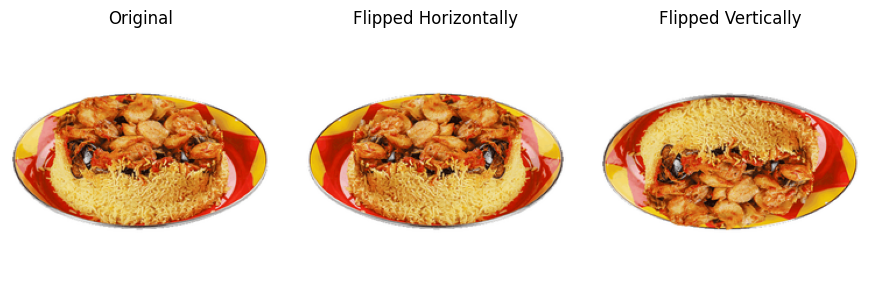

In [ ]:
idx = 190
plt.figure(figsize=(9,3))
plt.subplot(1,3,1); plt.imshow(X[idx]); plt.title("Original"); plt.axis('off')
plt.subplot(1,3,2); plt.imshow(np.fliplr(X[idx])); plt.title("Flipped Horizontally"); plt.axis('off')
plt.subplot(1,3,3); plt.imshow(np.flipud(X[idx])); plt.title("Flipped Vertically"); plt.axis('off')
plt.tight_layout(); plt.show()


# **Exploratory primary Data Analysis (EDA):**




> **Descriptive Statistics:**


This step summarizes numerical and categorical variables to understand data distribution before visualization.

In [ ]:
# Compute summary statistics for numerical variables
summary_stats = df[['protein_g', 'carbs_g', 'fat_g', 'calories_kcal']].describe().T
summary_stats['median'] = df[['protein_g', 'carbs_g', 'fat_g', 'calories_kcal']].median()

# Display summaries
display(summary_stats)


,count,mean,std,min,25%,50%,75%,max,median
protein_g,615.0,32.741463,36.177021,0.0,7.0,23.5,43.2,193.7,23.5
carbs_g,615.0,83.344878,90.494318,0.0,23.0,55.8,105.0,534.3,55.8
fat_g,615.0,40.392195,46.946556,0.0,12.4,25.0,48.9,307.7,25.0
calories_kcal,615.0,821.892683,833.186401,25.0,269.0,577.0,980.0,5181.0,577.0


In [ ]:
# Compute summary statistics for categorical variables
categorical_summary_df = df.describe(exclude="number")
# Display summaries
display(categorical_summary_df)

,Dish Name,image
count,615,615
unique,204,615
top,Cheese Sambosa,Primary_Images/Salty Sabeeb_204_aug1.jpg
freq,6,1


**Observations:**


Numerical variables (nutrition):

**Calories**: Median ≈ 577 kcal per dish; most dishes fall between 269–980 kcal (IQR). The spread is large (std ≈ 835) with a long right tail (max ≈ 5,181 kcal), reflecting varied portion sizes and rich dishes.

**Protein**: Median ≈ 23.5 g with IQR 7.0–43.2 g. A few dishes are very high in protein (max ≈ 193.7 g). Some entries show 0 g, likely sparse/rounded values rather than true zeros.

**Carbs**: Median ≈ 55.8 g, wide variability (std ≈ 90.6) and a heavy right tail (max ≈ 534.3 g).

**Fat**: Median ≈ 25.0 g with IQR 12.4–48.9 g; max ≈ 307.7 g.

Takeaway: Distributions are right-skewed with large variability, which is typical for heterogeneous recipes. We should consider scaling before modeling.

Categorical variables:

**Dish Name**: 205 rows, 204 unique names. The only repeated name is “Cheese Sambosa” (freq = 2), coming from different sources—we kept both because their nutrition differs.

**Image**: 205 unique image paths after consolidation into the all_images/ folder, confirming a one-image-per-row structure for modeling.

>**Graphical Univariate Analysis**

The histograms and boxplots were used to analyze the distribution and spread of each nutritional variable.
Histograms show the frequency of different values and help identify skewness in the data,
while boxplots highlight the range and detect any outliers.
These visualizations provide a clear overview of how calories, protein, fat, and carbs vary across the dishes.

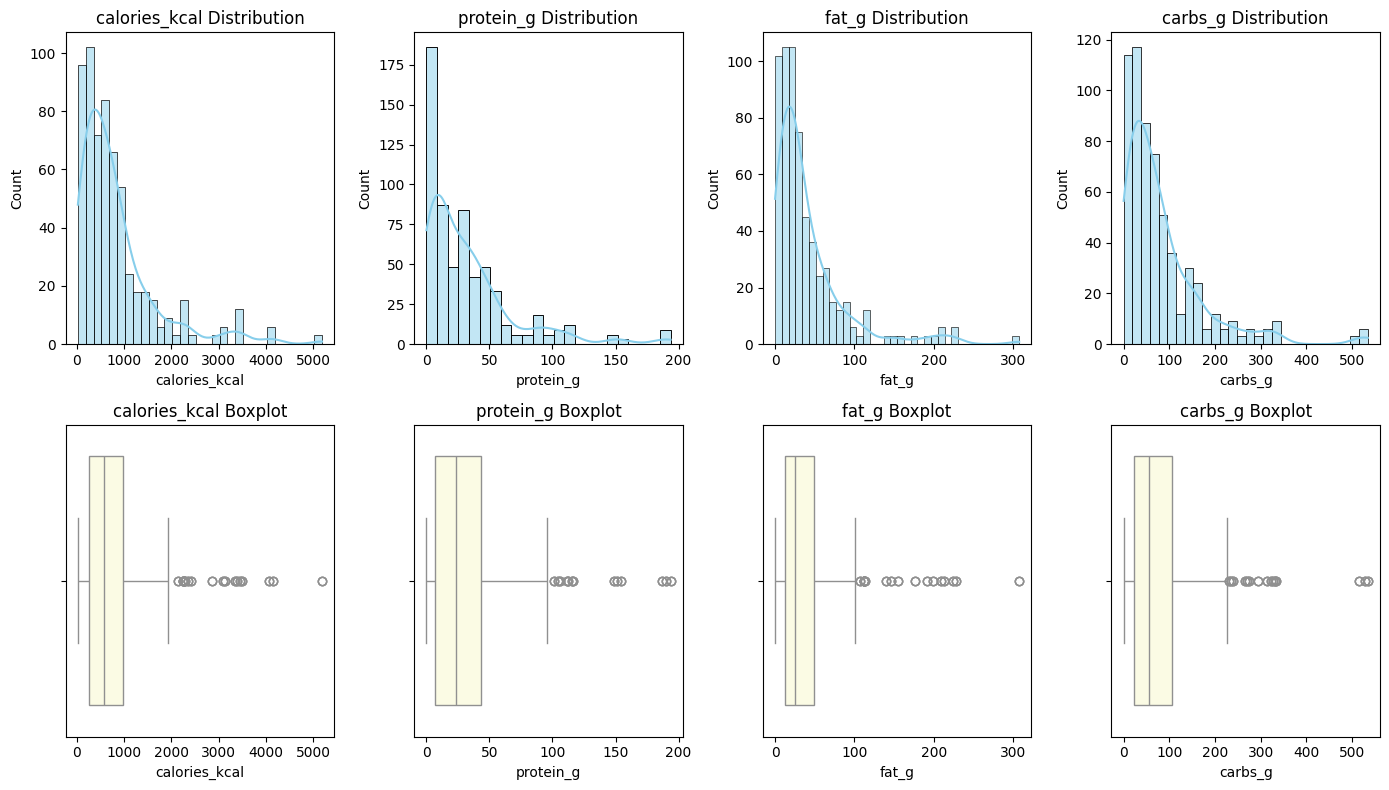

In [ ]:
num_cols = ['calories_kcal', 'protein_g', 'fat_g', 'carbs_g']

plt.figure(figsize=(14, 8))
for i, col in enumerate(num_cols):
    plt.subplot(2, 4, i+1)
    sns.histplot(df[col], kde=True, color='skyblue')
    plt.title(f'{col} Distribution')

    plt.subplot(2, 4, i+5)
    sns.boxplot(x=df[col], color='lightyellow')
    plt.title(f'{col} Boxplot')

plt.tight_layout()
plt.show()


*   **calories:** The distribution is strongly right-skewed, most dishes sit below ~1,000 kcal, with a long tail of high-calorie meals. Boxplots show several extreme outliers (multi-thousand kcal), likely large desserts or fried/creamy dishes.
*   **Protein:** is also right-skewed. Many dishes have modest protein (≤40 g), while a smaller subset reaches very high values (>100 g). Outliers suggest protein-dense items (meat/cheese heavy). Median << mean, confirming the tail effect.
*   **Fat:** The distribution is right-skewed. Most dishes fall in a low–to–moderate fat range (roughly 0–60g), with a long tail toward higher values. There are clear outliers above ~150–200g.
*   **Carbs:** The distribution is right-skewed and shows the widest spread, with a long right tail.Many dishes cluster under ~100 g, but there are notable outliers (>300–500 g), consistent with (rice/pasta/bread) based meals. Boxplots confirm multiple high-carb extremes.



>**Correlation Analysis**

The correlation matrix and heatmap were used to measure how strongly the nutritional variables are related to each other.

In [ ]:
corr = df[['calories_kcal', 'protein_g', 'fat_g', 'carbs_g']].corr()
corr

,calories_kcal,protein_g,fat_g,carbs_g
calories_kcal,1.000000,0.736774,0.948958,0.905707
protein_g,0.736774,1.000000,0.649425,0.533627
fat_g,0.948958,0.649425,1.000000,0.762006
carbs_g,0.905707,0.533627,0.762006,1.000000


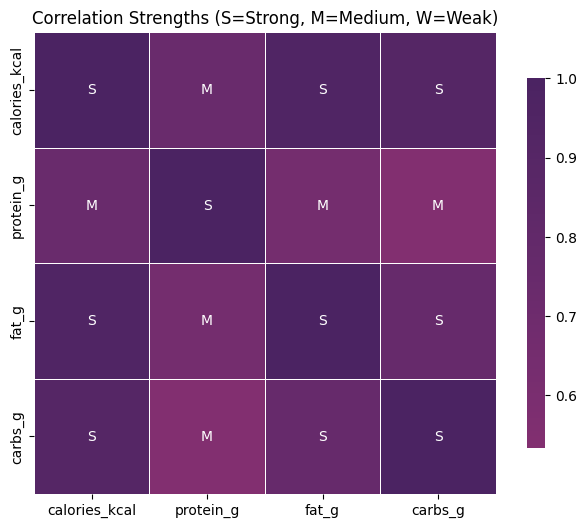

In [ ]:
#Create labels(S=Strong, M=Medium, W=Weak)
labels = np.where(np.abs(corr) > 0.75, "S",
          np.where(np.abs(corr) > 0.5, "M",
          np.where(np.abs(corr) > 0.25, "W", "")))
# Draw a heatmap using the above strength labels as annotations
plt.figure(figsize=(8,6))
sns.heatmap(corr, annot=labels, fmt='', cmap='flare', center=0,
            linewidths=.5, cbar_kws={"shrink": 0.8}, square=True)
plt.title("Correlation Strengths (S=Strong, M=Medium, W=Weak)")
plt.show()


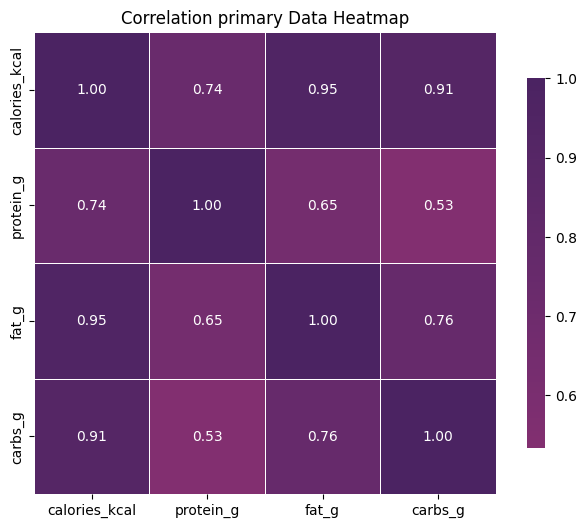

In [ ]:
#heatmap

plt.figure(figsize=(8,6))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap='flare',
    center=0,
    linewidths=.5,
    cbar_kws={"shrink": 0.8},
    square=True
)
plt.title("Correlation primary Data Heatmap")
plt.show()

**Correlation Analysis Summary (Detailed Explanation)**:

The correlation matrix and heatmap together reveal strong relationships among the nutritional variables.

**Calories and Fat (r = 0.95):** This is the strongest positive correlation in the dataset, meaning that dishes with higher fat content almost always have higher calorie values.

**Calories and Carbs (r = 0.91):** Also a strong positive correlation, showing that carbohydrates are another major contributor to total calories.

**Calories and Protein (r = 0.74):** This is a moderate-to-strong correlation, indicating that protein contributes to calories but less consistently compared to fat and carbs.

**Fat and Carbs (r = 0.76):** A strong correlation suggesting that many dishes with high fat also tend to be rich in carbohydrates.

Overall, both the table and the heatmap show that fat and carbohydrates are the dominant factors affecting total calorie levels, while protein plays a moderate role.
This insight is important for the regression model, as it highlights which features most influence calorie prediction.



---



> **Top and lowest 10 dishes by calories**




We extract the ten most and lowest calorie dishes and visualize them as a horizontal ranking. This makes it easy to spot which items sit at the very top and Bottom of the calorie spectrum.





/tmp/ipython-input-2872072670.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top10, y='Dish Name', x='calories_kcal', palette='magma')


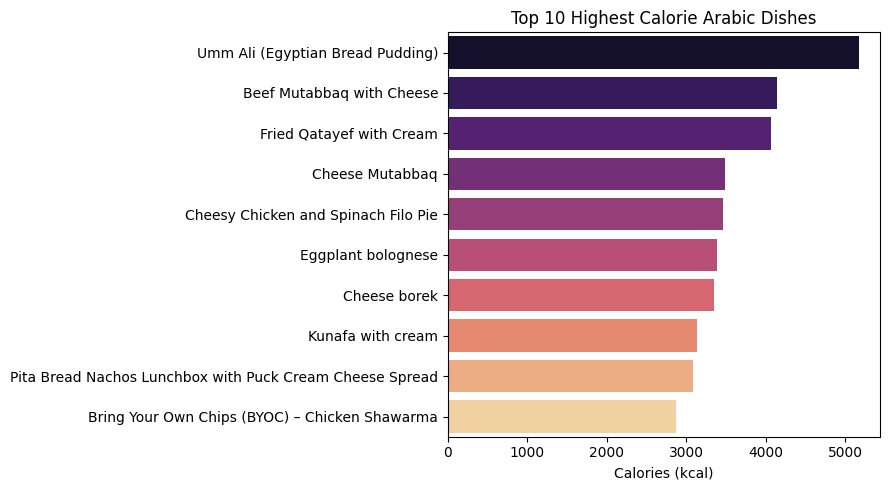

,Dish Name,calories_kcal
196,Umm Ali (Egyptian Bread Pudding),5181
20,Beef Mutabbaq with Cheese,4147
74,Fried Qatayef with Cream,4068
29,Cheese Mutabbaq,3495
34,Cheesy Chicken and Spinach Filo Pie,3458


In [ ]:
dish_max = (
    df.groupby('Dish Name', as_index=False)['calories_kcal']
      .max()
)


top10 = dish_max.nlargest(10, 'calories_kcal') \
                .sort_values('calories_kcal', ascending=False)

#  horizontal bar chart
plt.figure(figsize=(9,5))
sns.barplot(data=top10, y='Dish Name', x='calories_kcal', palette='magma')
plt.title('Top 10 Highest Calorie Arabic Dishes')
plt.xlabel('Calories (kcal)')
plt.ylabel('')
plt.tight_layout()
plt.show()

display(top10.head(5))


The plot shows a clear cluster of extremely high calorie dishes, led by rich desserts and cheese/cream-based items. A few entries (e.g., Umm Ali, Mutabbaq variants, and stuffed/creamed pastries) stand far above the rest, indicating strong contributions from fats and carbohydrates.

/tmp/ipython-input-548490927.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=low10, y='Dish Name', x='calories_kcal', palette='BuPu')


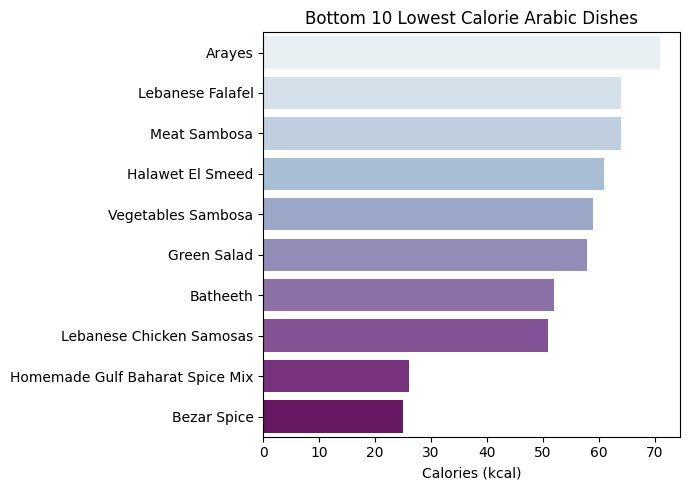

,Dish Name,calories_kcal
23,Bezar Spice,25
89,Homemade Gulf Baharat Spice Mix,26
116,Lebanese Chicken Samosas,51
18,Batheeth,52
76,Green Salad,58


In [ ]:
dish_min = (
    df.groupby('Dish Name', as_index=False)['calories_kcal']
      .min()
)
# Get the 10 dishes with the lowest calories
low10 = dish_min.nsmallest(10, 'calories_kcal').sort_values('calories_kcal', ascending=False)
plt.figure(figsize=(7,5))
# Plot a horizontal bar chart of the lowest-calorie dishes
sns.barplot(data=low10, y='Dish Name', x='calories_kcal', palette='BuPu')
plt.title('Bottom 10 Lowest Calorie Arabic Dishes')
plt.xlabel('Calories (kcal)'); plt.ylabel('')
plt.tight_layout(); plt.show()
# Also display a small table: the bottom 5 (sorted ascending by calories)
display(low10.sort_values('calories_kcal').head(5))

The bottom-calorie dishes cluster around 25–70 kcal each and are mostly condiments or small sides rather than full meals. The very lowest are spice mixes (e.g., Bezar Spice, Gulf Baharat), which add strong flavor for negligible energy and minimal macronutrients. Light sides like Green Salad and some Batheeth variants also stay low-kcal, with little fat and only modest carbs. These items are great for boosting taste and variety without many calories, but they contribute limited protein or satiety on their own; in practice, they’re best paired with a higher-protein main or more substantial components to meet nutritional needs.



> **Protein density (protein per calorie)**



/tmp/ipython-input-129339232.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_dense, y='Dish Name', x='protein_per_100kcal', palette='mako')


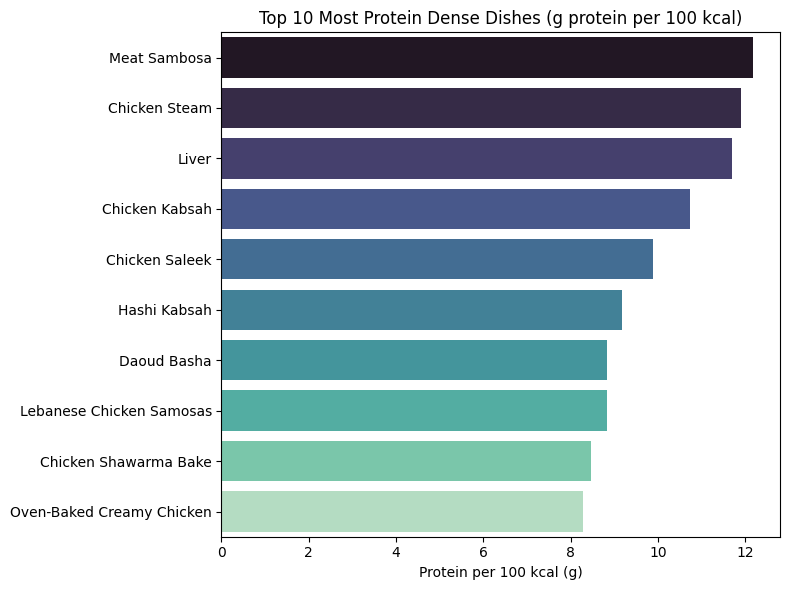

,Dish Name,protein_per_100kcal
129,Meat Sambosa,12.187500
47,Chicken Steam,11.898455
121,Liver,11.706587
39,Chicken Kabsah,10.730932
44,Chicken Saleek,9.886968


In [ ]:
# Protein density (protein per calorie)
# Make copy and compute grams of protein per 100 kcal
df_prot = df.copy()

# avoid divide-by-zero
df_prot = df_prot.replace([np.inf, -np.inf], np.nan)
df_prot = df_prot.dropna(subset=['protein_g', 'calories_kcal'])


# grams of protein per 100 kcal
df_prot['protein_per_100kcal'] = (df_prot['protein_g'] / df_prot['calories_kcal']) * 100


dense_per_dish = (
    df_prot.groupby('Dish Name', as_index=False)['protein_per_100kcal']
           .max()
)

# Top 10 most protein-dense *unique* dishes
top_dense = (dense_per_dish
             .nlargest(10, 'protein_per_100kcal')
             .sort_values('protein_per_100kcal', ascending=False))

plt.figure(figsize=(8,6))
sns.barplot(data=top_dense, y='Dish Name', x='protein_per_100kcal', palette='mako')
plt.title('Top 10 Most Protein Dense Dishes (g protein per 100 kcal)')
plt.xlabel('Protein per 100 kcal (g)'); plt.ylabel('')
plt.tight_layout(); plt.show()

# table:
display(top_dense.head(5))


Most Protein-Dense Dishes (g protein per 100 kcal):

The leaders are Meat Sambosa (≈12.2 g/100 kcal), Chicken Steam (≈11.9), and Liver (≈11.7), followed by Chicken Kabsah (≈10.7) and Chicken Saleek (≈9.9).

These dishes deliver a lot of protein for each calorie—typically ~9–12 g per 100 kcal, which is high compared with the rest of the dataset.

A clear pattern appears: lean, animal-protein–centric preparations (steamed chicken, liver, plain meat fillings) rank higher than creamy or pastry-heavy Dishes. Even when fat is present, the calorie denominator stays moderate, keeping protein density high.

these Dishes are efficient choices for protein (e.g., training/weight-management contexts).

/tmp/ipython-input-2176924249.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=bottom_dense, y='Dish Name', x='protein_per_100kcal', palette='PuRd')


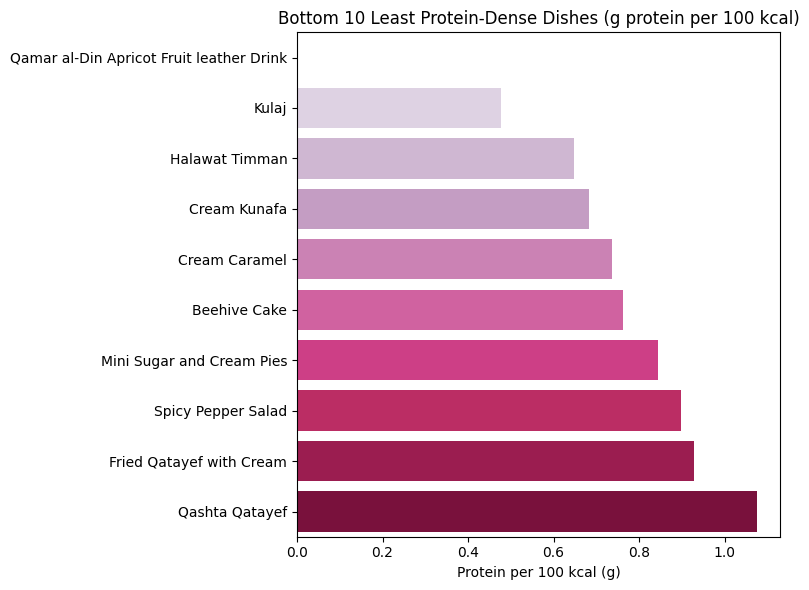

,Dish Name,protein_per_100kcal
164,Qamar al-Din Apricot Fruit leather Drink,0.000000
104,Kulaj,0.476190
78,Halawat Timman,0.648649
53,Cream Kunafa,0.681818
52,Cream Caramel,0.736842


In [ ]:
# Bottom 10 least protein-dense dishes (unique per Dish Name)
bottom_dense = (
    dense_per_dish
      .nsmallest(10, 'protein_per_100kcal')
      .sort_values('protein_per_100kcal')
)

plt.figure(figsize=(8,6))
sns.barplot(data=bottom_dense, y='Dish Name', x='protein_per_100kcal', palette='PuRd')
plt.title('Bottom 10 Least Protein-Dense Dishes (g protein per 100 kcal)')
plt.xlabel('Protein per 100 kcal (g)'); plt.ylabel('')
plt.tight_layout(); plt.show()

# table:
display(bottom_dense.head(5))


The bottom protein-density list (measured as grams of protein per 100 kcal) is dominated by desserts, sweet drinks, and cream-based pastries. The lowest entry, Qamar al-Din (apricot fruit leather drink), provides ≈0 g protein / 100 kcal, reflecting that it’s essentially pure carbohydrate calories. Items like Kulaj, Halawat Timman, Cream Kunafa, and Cream Caramel also show very low protein per calorie (≈0.48–0.74 g/100 kcal) because their energy largely comes from sugars and/or fats with only modest protein. In practical terms, these dishes contribute calories with minimal protein satiety value; they should be considered “treats” rather than protein sources.



# **Secondary Data:**



> **Load the Secondary dataset**




In [ ]:
!pip -q install kaggle
# Open a file picker in Colab to upload your Kaggle API key (kaggle.json)
from google.colab import files
files.upload()
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json


Saving kaggle.json to kaggle.json


In [ ]:
# Download the entire dataset as a single ZIP file to /content using the Kaggle CLI
!kaggle datasets download -d nutritionverse/nutritionverse-real -p /content
!unzip -q /content/nutritionverse-real.zip -d /content/nutritionverse-real
!find /content/nutritionverse-real -maxdepth 2 -type d -print


Dataset URL: https://www.kaggle.com/datasets/nutritionverse/nutritionverse-real
License(s): CC-BY-NC-SA-4.0
100% 1.03G/1.03G [00:19<00:00, 91.2MB/s]
100% 1.03G/1.03G [00:19<00:00, 57.3MB/s]
/content/nutritionverse-real
/content/nutritionverse-real/nutritionverse-manual
/content/nutritionverse-real/nutritionverse-manual/nutritionverse-manual


In [ ]:
import pandas as pd, os, glob

csv_path = "/content/nutritionverse-real/nutritionverse_dish_metadata3.csv"
Secondary = pd.read_csv(csv_path)
# Keep only the columns we care about (drop everything else)
wanted = ['dish_id','total_calories', 'total_fats', 'total_carbohydrates', 'total_protein']
keep = [c for c in wanted if c in Secondary.columns]
Secondary = Secondary[keep].copy()

# Rename columns
rename_map = {
    'dish_id': 'dish_id',
    'total_calories': 'calories_kcal',
    'total_fats': 'fat_g',
    'total_carbohydrates': 'carbs_g',
    'total_protein': 'protein_g'
}
Secondary = Secondary.rename(columns=rename_map)

# Reorder columns
Secondary = Secondary[['dish_id', 'calories_kcal', 'fat_g', 'carbs_g', 'protein_g']]

# Ensure numeric types
for c in ['calories_kcal', 'fat_g', 'carbs_g', 'protein_g']:
    Secondary[c] = pd.to_numeric(Secondary[c], errors='coerce')


Secondary.head()


,dish_id,calories_kcal,fat_g,carbs_g,protein_g
0,1,95.73,0.3336,22.7958,0.5049
1,2,186.99,1.8662,21.1603,19.8902
2,3,92.04,0.3120,21.9336,0.4212
3,4,74.76,0.7224,0.0000,15.9600
4,5,399.10,16.3631,42.4888,20.0778


In [ ]:
IMG_DIR = "image_nutritionverse-real"
#Given a dish_id , search the images folder for a file that matches the dataset’s naming convention and return the first matching file path.
#If no image is found, return an empty string.
def find_image_for_dish(dish_id: int) -> str:
    patterns = [
        f"dish_{int(dish_id)}_*.jpg",
        f"dish_{int(dish_id)}_*.jpeg",
        f"dish_{int(dish_id)}_*.png",
    ]
    for pat in patterns:
        hits = glob.glob(os.path.join(IMG_DIR, pat))
        if hits:
            return hits[0]
    return ""

Secondary["image"] = Secondary["dish_id"].apply(find_image_for_dish)
print("Missing images:", (Secondary["image"] == "").sum())
Secondary.head()


Missing images: 26


,dish_id,calories_kcal,fat_g,carbs_g,protein_g,image
0,1,95.73,0.3336,22.7958,0.5049,
1,2,186.99,1.8662,21.1603,19.8902,image_nutritionverse-real/dish_2_IMG_7112_jpeg...
2,3,92.04,0.3120,21.9336,0.4212,
3,4,74.76,0.7224,0.0000,15.9600,
4,5,399.10,16.3631,42.4888,20.0778,


In [ ]:
# Save
Secondary.to_csv('NutritionVerse_Real.csv', index=False, encoding='utf-8-sig')
print(" Saved: NutritionVerse_Real.csv")

 Saved: NutritionVerse_Real.csv


# **Exploratory Data Analysis (EDA) for secondary data:**

In [ ]:
#Load the Secondary dataset
Secondary = pd.read_csv('NutritionVerse_Real.csv')

In [ ]:
missing_values = Secondary.isnull().sum()  # Count missing values per column
total_missing = missing_values.sum()  # Total missing values in the dataset

if total_missing == 0:
    print("No missing values found in the dataset!")
else:
    print("Missing values detected!")
    print(missing_values)  # Display columns

Missing values detected!
dish_id           0
calories_kcal     0
fat_g             0
carbs_g           0
protein_g         0
image            26
dtype: int64


In [ ]:
#nutrition columns
cols = ['calories_kcal', 'protein_g', 'carbs_g', 'fat_g']
# Find every row where ANY of the four nutrition columns equals 0
zero_rows = Secondary[(Secondary[cols] == 0).any(axis=1)]

print("Number of rows containing at least one zero:", len(zero_rows))
zero_rows

Number of rows containing at least one zero: 11


,dish_id,calories_kcal,fat_g,carbs_g,protein_g,image
3,4,74.76,0.7224,0.0,15.9600,NaN
22,23,659.68,36.2026,0.0,78.8158,image_nutritionverse-real/dish_23_IMG_5706_jpe...
38,39,218.96,10.6981,0.0,28.5957,image_nutritionverse-real/dish_39_IMG_6543_jpe...
52,53,347.48,16.6344,0.0,46.3736,NaN
91,92,1633.33,100.6636,0.0,181.7693,image_nutritionverse-real/dish_92_IMG_8196_jpe...
99,100,3266.66,201.3272,0.0,363.5386,image_nutritionverse-real/dish_100_IMG_8464_jp...
115,116,235.20,9.7536,0.0,33.5520,image_nutritionverse-real/dish_116_IMG_9060_jp...
121,122,176.64,8.6304,0.0,23.0688,image_nutritionverse-real/dish_122_IMG_9204_jp...
154,155,418.88,28.2480,0.0,38.6144,image_nutritionverse-real/dish_155_IMG_0399_jp...
185,186,481.11,20.7842,0.0,67.3195,image_nutritionverse-real/dish_186_IMG_1468_jp...


We do not have a row that has all the nutritional values ​​zeroed so we did not remove any row.

In [ ]:
# - Convert empty strings ("" or whitespace) to NaN so dropna can catch them.
Secondary['image'] = Secondary['image'].replace(r'^\s*$', np.nan, regex=True)
# Drop rows with missing images (NaN in the 'image' column).
before = len(Secondary)
Secondary = Secondary.dropna(subset=['image'])
after = len(Secondary)
print(f"Removed {before - after} rows with missing images.")

Removed 26 rows with missing images.


In [ ]:
# Number of duplicated rows
print("Total number of duplicated rows: " + str(sum(Secondary.duplicated(subset=['dish_id'], keep=False))))

Total number of duplicated rows: 0


In [ ]:
#save the cleaned dataset .
Secondary.to_csv("NutritionVerse_Real_cleaned.csv", index=False, encoding="utf-8-sig")
print("Saved: NutritionVerse_Real_cleaned.csv")

Saved: NutritionVerse_Real_cleaned.csv




> **Descriptive Statistics for secondary data :**



In [ ]:
# Compute summary statistics for numerical variables
summary_stats = Secondary[['protein_g', 'carbs_g', 'fat_g', 'calories_kcal']].describe().T
summary_stats['median'] = Secondary[['protein_g', 'carbs_g', 'fat_g', 'calories_kcal']].median()

# Display summaries
display(summary_stats)

,count,mean,std,min,25%,50%,75%,max,median
protein_g,225.0,65.907278,71.404371,0.4212,21.165600,50.5005,84.825993,391.324859,50.5005
carbs_g,225.0,62.932746,95.029413,0.0000,14.504000,31.0680,62.649000,430.216000,31.0680
fat_g,225.0,40.002823,46.129248,0.0644,12.548417,25.9161,43.037000,227.130676,25.9161
calories_kcal,225.0,866.622351,856.617214,23.4000,352.260000,576.7000,893.470000,3724.150000,576.7000


In [ ]:
# Compute summary statistics for categorical variables
categorical_summary_Secondary = Secondary.describe(exclude="number")
# Display summaries
display(categorical_summary_Secondary)

,image
count,225
unique,225
top,image_nutritionverse-real/dish_2_IMG_7112_jpeg...
freq,1


>**Graphical Univariate Analysis for secondary data**

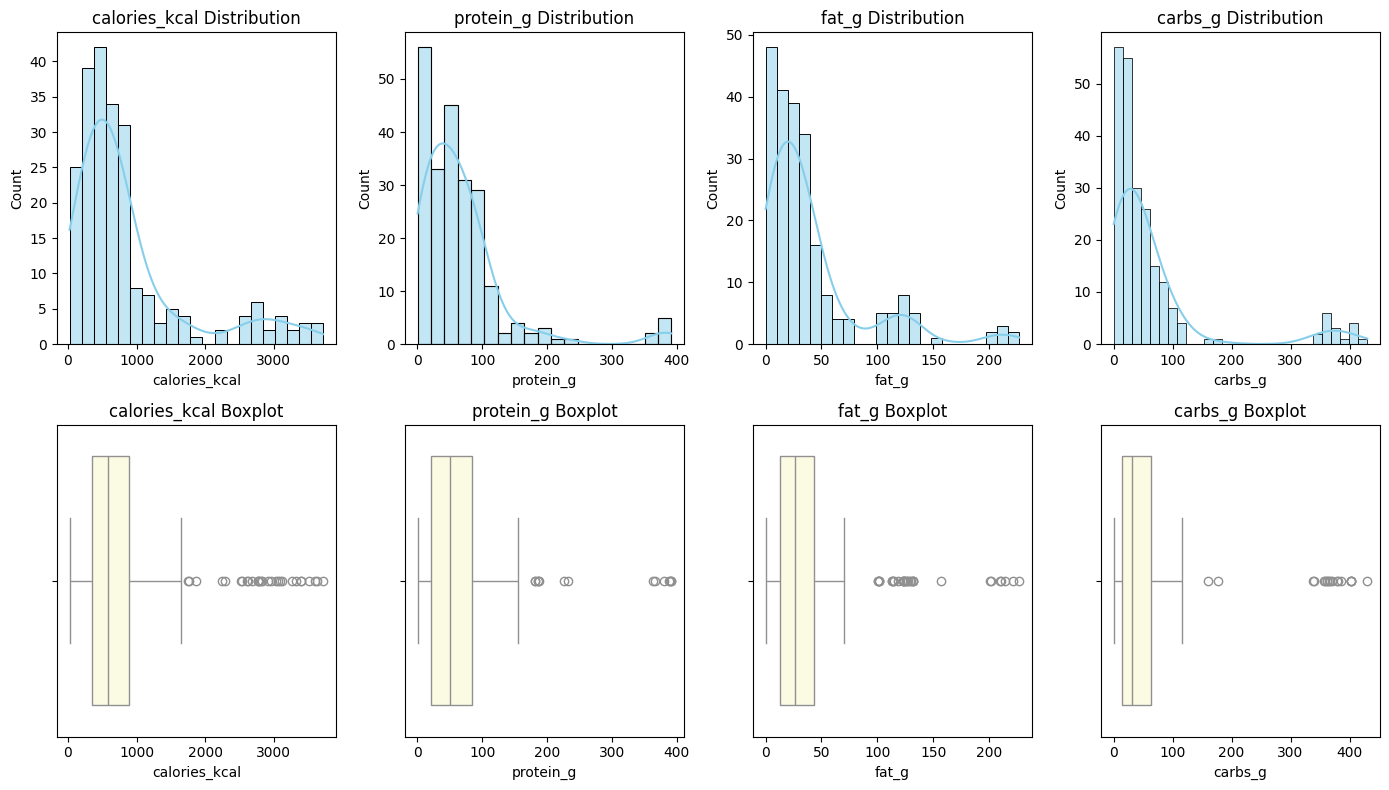

In [ ]:
num_cols = ['calories_kcal', 'protein_g', 'fat_g', 'carbs_g']

plt.figure(figsize=(14, 8))
for i, col in enumerate(num_cols):
    plt.subplot(2, 4, i+1)
    sns.histplot(Secondary[col], kde=True, color='skyblue')
    plt.title(f'{col} Distribution')

    plt.subplot(2, 4, i+5)
    sns.boxplot(x=Secondary[col], color='lightyellow')
    plt.title(f'{col} Boxplot')

plt.tight_layout()
plt.show()


**Calories:** The distribution strongly right-skewed. Most dishes fall roughly between ~250–900 kcal, with a long upper tail and several high-calorie outliers in the boxplot, indicating a small set of very energy-dense plates.

**Protein :** Also right-skewed. The bulk of dishes cluster around ~10–60 g, while a few items reach >200–300 g, appearing as clear high-protein outliers.

**Fat :** Shows a pronounced right skew. Many plates are in the ~10–60 g range; a thinner tail extends past ~200 g, with multiple upper-end outliers visible in the boxplot.

**Carbs :** Right-skewed with the widest spread. Most dishes are <100–120 g, but there are notable high-carb points (>300–400 g)—consistent with grain/starch-heavy meals. The boxplot confirms several extreme carbohydrate values.

>**Correlation Analysis for secondary data**

In [ ]:
corr_Secondary =Secondary[['calories_kcal', 'protein_g', 'fat_g', 'carbs_g']].corr()
corr_Secondary

,calories_kcal,protein_g,fat_g,carbs_g
calories_kcal,1.000000,0.714906,0.974063,0.673882
protein_g,0.714906,1.000000,0.816578,-0.023584
fat_g,0.974063,0.816578,1.000000,0.514228
carbs_g,0.673882,-0.023584,0.514228,1.000000


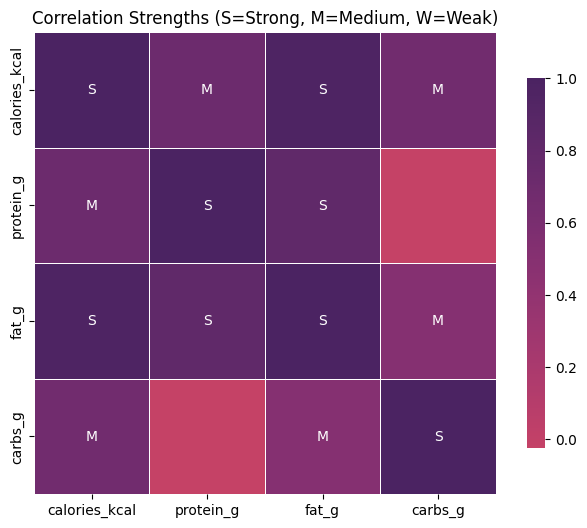

In [ ]:
#Create labels(S=Strong, M=Medium, W=Weak)
labels = np.where(np.abs(corr_Secondary) > 0.75, "S",
          np.where(np.abs(corr_Secondary) > 0.5, "M",
          np.where(np.abs(corr_Secondary) > 0.25, "W", "")))
# Draw a heatmap using the above strength labels as annotations
plt.figure(figsize=(8,6))
sns.heatmap(corr_Secondary, annot=labels, fmt='', cmap='flare', center=0,
            linewidths=.5, cbar_kws={"shrink": 0.8}, square=True)
plt.title("Correlation Strengths (S=Strong, M=Medium, W=Weak)")
plt.show()

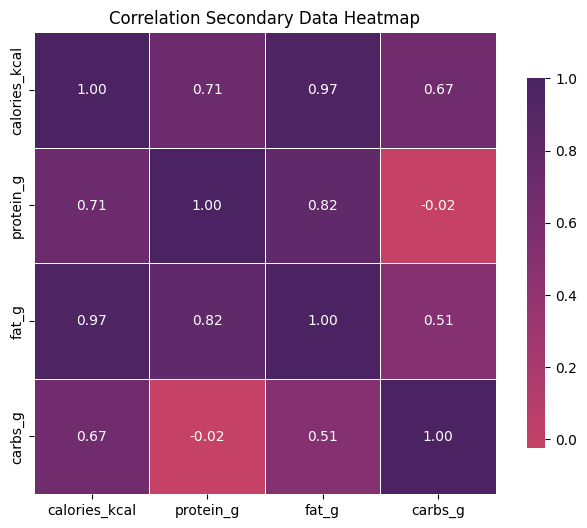

In [ ]:
#heatmap

plt.figure(figsize=(8,6))
sns.heatmap(
    corr_Secondary,
    annot=True,
    fmt=".2f",
    cmap='flare',
    center=0,
    linewidths=.5,
    cbar_kws={"shrink": 0.8},
    square=True
)
plt.title("Correlation Secondary Data Heatmap")
plt.show()


We can observe that:

**Very strong positive:** Calories & Fat (r ≈ 0.97) — Higher fat almost always means higher total calories.

**Strong positive:** Calories & Protein (r ≈ 0.71) — More protein generally raises calories, though less tightly than fat.

**Moderate–strong positive:** Calories & Carbs (r ≈ 0.67) — Carbohydrates also push calories up, with more variability.

**Strong positive:** Protein & Fat (r ≈ 0.82) — Many dishes combine both (e.g., meat/dairy–based plates).

**Moderate positive:** Fat & Carbs (r ≈ 0.51) — Some items are both fatty and carb-dense (fried/pastry dishes), but not consistently.

**Negligible/none:** Protein & Carbs (r ≈ −0.02) — High-protein dishes are not necessarily high-carb (and vice versa).

# **Compare Key Metrics**

**Summary Statistics Comparison Between Primary and Secondary Datasets**



- **Protein content** is nearly double in the secondary dataset (**65.91g** vs. **32.74g**), suggesting that secondary sources may represent larger portion sizes or more protein-dense dishes.  
- **Carbohydrate levels** are higher in the primary dataset (**83.34g** vs. **62.93g**), which may reflect differences in dish types—such as a higher prevalence of rice-based meals.  
- **Fat content** appears consistent across both datasets (**~40g**), indicating similar fat profiles in the sampled dishes.  
- **Caloric values** show comparable medians (**~577 kcal**), despite a slight difference in mean values (**866.62** vs. **821.89**), suggesting similar central tendencies in energy content.

**Possible Reasons for These Differences:**

- **Variations in data collection methods** (e.g., manual entry vs. nutrition APIs)  
- **Differences in dish composition** between datasets  
- **Discrepancies in serving sizes** or regional variations in recipes
**


**Comparison of Primary and Secondary Data**


| Feature             | Mean (Primary) | Median (Primary) | Mean (Secondary) | Median (Secondary) |
| ------------------- | -------------- | ---------------- | ---------------- | ------------------ |
| **Protein (g)**     | 32.74          | 23.5             | 65.91            | 50.5               |
| **Carbs (g)**       | 83.34          | 55.8             | 62.93            | 31.1               |
| **Fat (g)**         | 40.39          | 25.0             | 40.00            | 25.9               |
| **Calories (kcal)** | 821.89         | 577.0            | 866.62           | 576.7              |


# **Phase 3**

In [ ]:
import pandas as pd
import numpy as np

In [ ]:

# 1) load primary
df_primary = pd.read_csv("dataset.csv")

# 2) load secondary NutritionVerse
df_secondary = pd.read_csv("NutritionVerse_Real_cleaned.csv")

df_primary['dish_id'] = np.nan
df_secondary['Dish Name'] = np.nan

# 4)  merge
df_all = pd.concat([df_primary, df_secondary], ignore_index=True)

# save
df_all.to_csv("full_dataset.csv", index=False)

print("save full_dataset.csv")

save full_dataset.csv


In [ ]:
import numpy as np

df_all['group'] = np.where(
    df_all['Dish Name'].notna(),   # primary
    df_all['Dish Name'],           # group = dish name
    df_all['dish_id'].astype(str)  #secondary group = dish_id
)



In [ ]:
# group
group_stats = (
    df_all
    .groupby('group')[['protein_g', 'calories_kcal', 'fat_g', 'carbs_g']]
    .mean()
    .reset_index()
)


In [ ]:
import numpy as np
from sklearn.cluster import KMeans
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.preprocessing import StandardScaler

nutri_cols = ['protein_g', 'calories_kcal', 'fat_g', 'carbs_g']

# Prepare clustering features from group_stats (only nutrition columns)

X = group_stats[nutri_cols].values

#  apply scaling before K-Means
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

#   Apply K-Means to create strata
k = 4   # number of nutritional strata (clusters)
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
group_stats['strata'] = kmeans.fit_predict(X_scaled)

print(group_stats['strata'].value_counts())


strata
3    260
0    126
2     34
1      9
Name: count, dtype: int64


In [ ]:
df_all_strata = df_all.merge(
    group_stats[['group', 'strata']],
    on='group',
    how='left'
)
groups = group_stats['group'].values
y_strata = group_stats['strata'].values
# Set up a stratified splitter so that the train/test split preserves the strata proportions
sss = StratifiedShuffleSplit(
    n_splits=1,
    test_size=0.20, # 20% of groups go to the test set
    random_state=42
)

for train_idx, test_idx in sss.split(groups, y_strata):
    train_groups = groups[train_idx]
    test_groups  = groups[test_idx]
# Build the final row-level train/test DataFrames:
# all rows whose group is in train_groups go to train_df, and similarly for test_df
train_df = df_all_strata[df_all_strata['group'].isin(train_groups)].copy()
test_df= df_all_strata[df_all_strata['group'].isin(test_groups)].copy()

print("Train shape:", train_df.shape)
print("Test  shape:", test_df.shape)

Train shape: (660, 9)
Test  shape: (180, 9)


In [ ]:
import tensorflow as tf
import numpy as np

# target
target_cols = ['protein_g', 'calories_kcal', 'fat_g', 'carbs_g']

# Convert image paths and labels from DataFrames to NumPy arrays
train_paths  = train_df['image'].values
train_labels = train_df[target_cols].values.astype('float32')

test_paths   = test_df['image'].values
test_labels  = test_df[target_cols].values.astype('float32')

IMG_SIZE = (224, 224)

def load_and_preprocess(path, label):
    # path: string
    # label: vector
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, IMG_SIZE)
    img = tf.cast(img, tf.float32) / 255.0             # normalize 0–1
    return img, label                                   # (224,224,3), (4,)

#   Dataset train
train_ds = tf.data.Dataset.from_tensor_slices((train_paths, train_labels))
train_ds = train_ds.map(load_and_preprocess,
                        num_parallel_calls=tf.data.AUTOTUNE)
train_ds = train_ds.shuffle(1000).batch(16).prefetch(tf.data.AUTOTUNE)

#  Dataset  test
test_ds = tf.data.Dataset.from_tensor_slices((test_paths, test_labels))
test_ds = test_ds.map(load_and_preprocess,
                      num_parallel_calls=tf.data.AUTOTUNE)
test_ds = test_ds.batch(16).prefetch(tf.data.AUTOTUNE)




> **Model 1:**



In [ ]:
import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import Input, GlobalAveragePooling2D, Dense
from tensorflow.keras.models import Model


In [ ]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import layers, models

#   MobileNetV2
base_model = MobileNetV2(
    include_top=False,
    weights='imagenet',           #   ImageNet
    input_shape=(224, 224, 3)
)

base_model.trainable = False

inputs = tf.keras.Input(shape=(224, 224, 3))
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(128, activation='relu')(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(4, name="nutri_outputs")(x)

mobilenet_model = tf.keras.Model(inputs, outputs)

#   compile  (Regression → MSE + MAE)
mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss='mse',
    metrics=['mae']
)

mobilenet_model.summary()


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ nutri_outputs (Dense)           │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,468 (9.24 MB)

 Trainable params: 164,484 (642.52 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
history = mobilenet_model.fit(
    train_ds,
    validation_data=test_ds,
    epochs=30
)


Epoch 1/30
42/42 ━━━━━━━━━━━━━━━━━━━━ 56s 1s/step - loss: 304178.2188 - mae: 223.2734 - val_loss: 355323.0312 - val_mae: 214.6626
Epoch 2/30
42/42 ━━━━━━━━━━━━━━━━━━━━ 69s 734ms/step - loss: 255061.8750 - mae: 194.0019 - val_loss: 275087.3438 - val_mae: 179.1076
Epoch 3/30
42/42 ━━━━━━━━━━━━━━━━━━━━ 44s 802ms/step - loss: 169092.5938 - mae: 157.2901 - val_loss: 238229.4688 - val_mae: 177.4326
Epoch 4/30
42/42 ━━━━━━━━━━━━━━━━━━━━ 45s 815ms/step - loss: 159490.8438 - mae: 163.8301 - val_loss: 233234.6250 - val_mae: 180.7012
Epoch 5/30
42/42 ━━━━━━━━━━━━━━━━━━━━ 80s 763ms/step - loss: 152917.6875 - mae: 170.2776 - val_loss: 230844.5938 - val_mae: 182.5503
Epoch 6/30
42/42 ━━━━━━━━━━━━━━━━━━━━ 85s 846ms/step - loss: 178116.2969 - mae: 179.5474 - val_loss: 229847.1562 - val_mae: 181.2771
Epoch 7/30
42/42 ━━━━━━━━━━━━━━━━━━━━ 76s 714ms/step - loss: 182508.0625 - mae: 178.5360 - val_loss: 228536.5938 - val_mae: 180.0333
Epoch 8/30
42/42 ━━━━━━━━━━━━━━━━━━━━ 40s 711ms/step - loss: 155854.9062

In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_true_list = []
y_pred_list = []

for batch_imgs, batch_labels in test_ds:
    y_true_list.append(batch_labels.numpy())                          # Actual
    y_pred_list.append(mobilenet_model.predict(batch_imgs, verbose=0))  #  Predicted

y_true = np.vstack(y_true_list)
y_pred = np.vstack(y_pred_list)


In [ ]:
y_pred_mobil = mobilenet_model.predict(test_ds)
metrics = {}

for i, col in enumerate(target_cols):
    mae  = mean_absolute_error(y_true[:, i], y_pred_mobil[:, i])
    mse  = mean_squared_error(y_true[:, i], y_pred_mobil[:, i])
    rmse = np.sqrt(mse)
    r2   = r2_score(y_true[:, i], y_pred_mobil[:, i])

    metrics[col] = {
        'MAE':  mae,
        'MSE':  mse,
        'RMSE': rmse,
        'R2':   r2
    }

results_df = pd.DataFrame(metrics).T   #  (rows = nutrients)
print("\nPer-target regression metrics:")
print(results_df)


12/12 ━━━━━━━━━━━━━━━━━━━━ 14s 1s/step

Per-target regression metrics:
                      MAE            MSE        RMSE        R2
protein_g       30.157341    2354.396484   48.522124  0.050645
calories_kcal  527.104919  798484.875000  893.579809  0.103020
fat_g           28.881990    2482.581543   49.825511  0.092670
carbs_g         57.897526   10825.938477  104.047770  0.090668


12/12 ━━━━━━━━━━━━━━━━━━━━ 9s 735ms/step


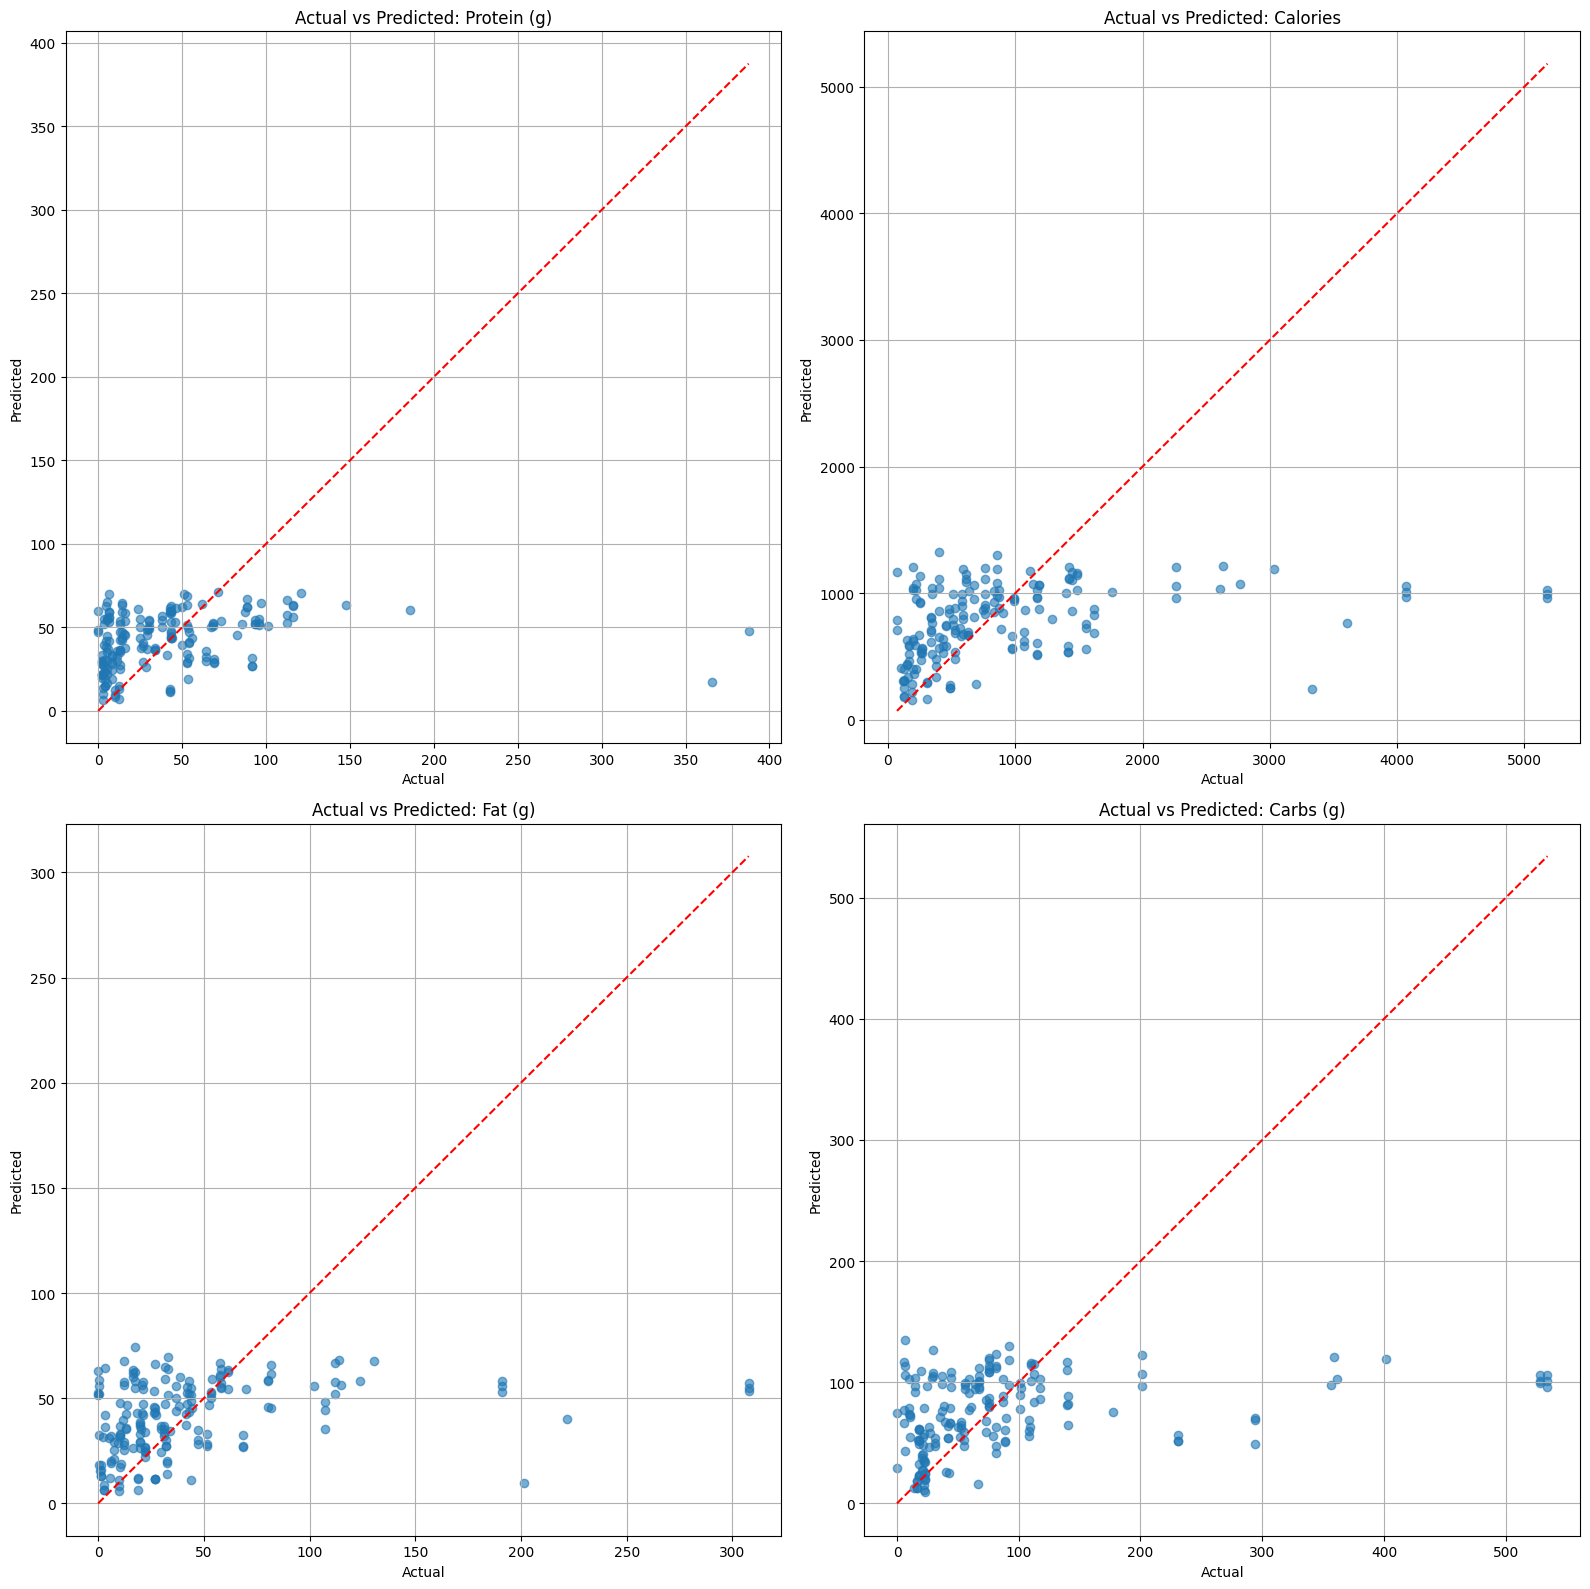

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

y_true  = test_labels
y_pred  = mobilenet_model.predict(test_ds)

nutrients = ['Protein (g)', 'Calories', 'Fat (g)', 'Carbs (g)']

plt.figure(figsize=(16, 16))

for i in range(4):
    plt.subplot(2, 2, i+1)
    plt.scatter(y_true[:, i], y_pred[:, i], alpha=0.6)

    #   y = x
    min_v = min(y_true[:, i].min(), y_pred[:, i].min())
    max_v = max(y_true[:, i].max(), y_pred[:, i].max())
    plt.plot([min_v, max_v], [min_v, max_v], 'r--')

    plt.title(f"Actual vs Predicted: {nutrients[i]}")
    plt.xlabel("Actual")
    plt.ylabel("Predicted")
    plt.grid(True)

plt.tight_layout()
plt.show()



> **Model 2 EfficientNet:**

In [ ]:
import tensorflow as tf
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras import layers, models

# 1)  EfficientNetB0 ( ImageNet)
base_model = EfficientNetB0(
    include_top=False,
    weights='imagenet',
    input_shape=(224, 224, 3)
)


base_model.trainable = False

# 2) EfficientNet
inputs = tf.keras.Input(shape=(224, 224, 3))
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(256, activation='relu')(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(4, name="nutri_outputs")(x)

efficientnet_model = models.Model(inputs, outputs)

# 3)  compile ( MSE + MAE)
efficientnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss='mse',
    metrics=['mae']
)

efficientnet_model.summary()


history_eff = efficientnet_model.fit(
    train_ds,
    validation_data=test_ds,
    epochs=30
)




16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ nutri_outputs (Dense)           │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,378,535 (16.70 MB)

 Trainable params: 328,964 (1.25 MB)

 Non-trainable params: 4,049,571 (15.45 MB)

Epoch 1/30
42/42 ━━━━━━━━━━━━━━━━━━━━ 82s 1s/step - loss: 303125.1250 - mae: 227.7378 - val_loss: 388470.1250 - val_mae: 233.5135
Epoch 2/30
42/42 ━━━━━━━━━━━━━━━━━━━━ 71s 1s/step - loss: 257979.6719 - mae: 198.6294 - val_loss: 322208.2812 - val_mae: 200.6317
Epoch 3/30
42/42 ━━━━━━━━━━━━━━━━━━━━ 79s 1s/step - loss: 230767.1562 - mae: 181.6964 - val_loss: 260519.9375 - val_mae: 176.9706
Epoch 4/30
42/42 ━━━━━━━━━━━━━━━━━━━━ 76s 1s/step - loss: 198237.6406 - mae: 168.1598 - val_loss: 233624.5625 - val_mae: 178.5733
Epoch 5/30
42/42 ━━━━━━━━━━━━━━━━━━━━ 69s 1s/step - loss: 184315.5469 - mae: 172.2962 - val_loss: 228796.4688 - val_mae: 182.2416
Epoch 6/30
42/42 ━━━━━━━━━━━━━━━━━━━━ 60s 1s/step - loss: 151399.1406 - mae: 165.8372 - val_loss: 227696.7344 - val_mae: 183.7966
Epoch 7/30
42/42 ━━━━━━━━━━━━━━━━━━━━ 69s 1s/step - loss: 167094.7656 - mae: 175.1298 - val_loss: 227814.3281 - val_mae: 183.4467
Epoch 8/30
42/42 ━━━━━━━━━━━━━━━━━━━━ 73s 1s/step - loss: 170547.1094 - mae: 174.0709 - va

In [ ]:

y_pred_eff = efficientnet_model.predict(test_ds)

metrics = {}

for i, col in enumerate(target_cols):
    mae  = mean_absolute_error(y_true[:, i], y_pred_eff[:, i])
    mse  = mean_squared_error(y_true[:, i], y_pred_eff[:, i])
    rmse = np.sqrt(mse)
    r2   = r2_score(y_true[:, i], y_pred_eff[:, i])

    metrics[col] = {
        'MAE':  mae,
        'MSE':  mse,
        'RMSE': rmse,
        'R2':   r2
    }

results_df = pd.DataFrame(metrics).T   # (rows = nutrients)
print("\nPer-target regression metrics:")
print(results_df)


12/12 ━━━━━━━━━━━━━━━━━━━━ 18s 1s/step

Per-target regression metrics:
                      MAE            MSE        RMSE        R2
protein_g       32.087605    2480.496582   49.804584 -0.000202
calories_kcal  608.012146  893630.250000  945.320184 -0.003862
fat_g           31.568289    2750.688232   52.447004 -0.005318
carbs_g         64.892662   11947.112305  109.302847 -0.003506


12/12 ━━━━━━━━━━━━━━━━━━━━ 12s 1s/step


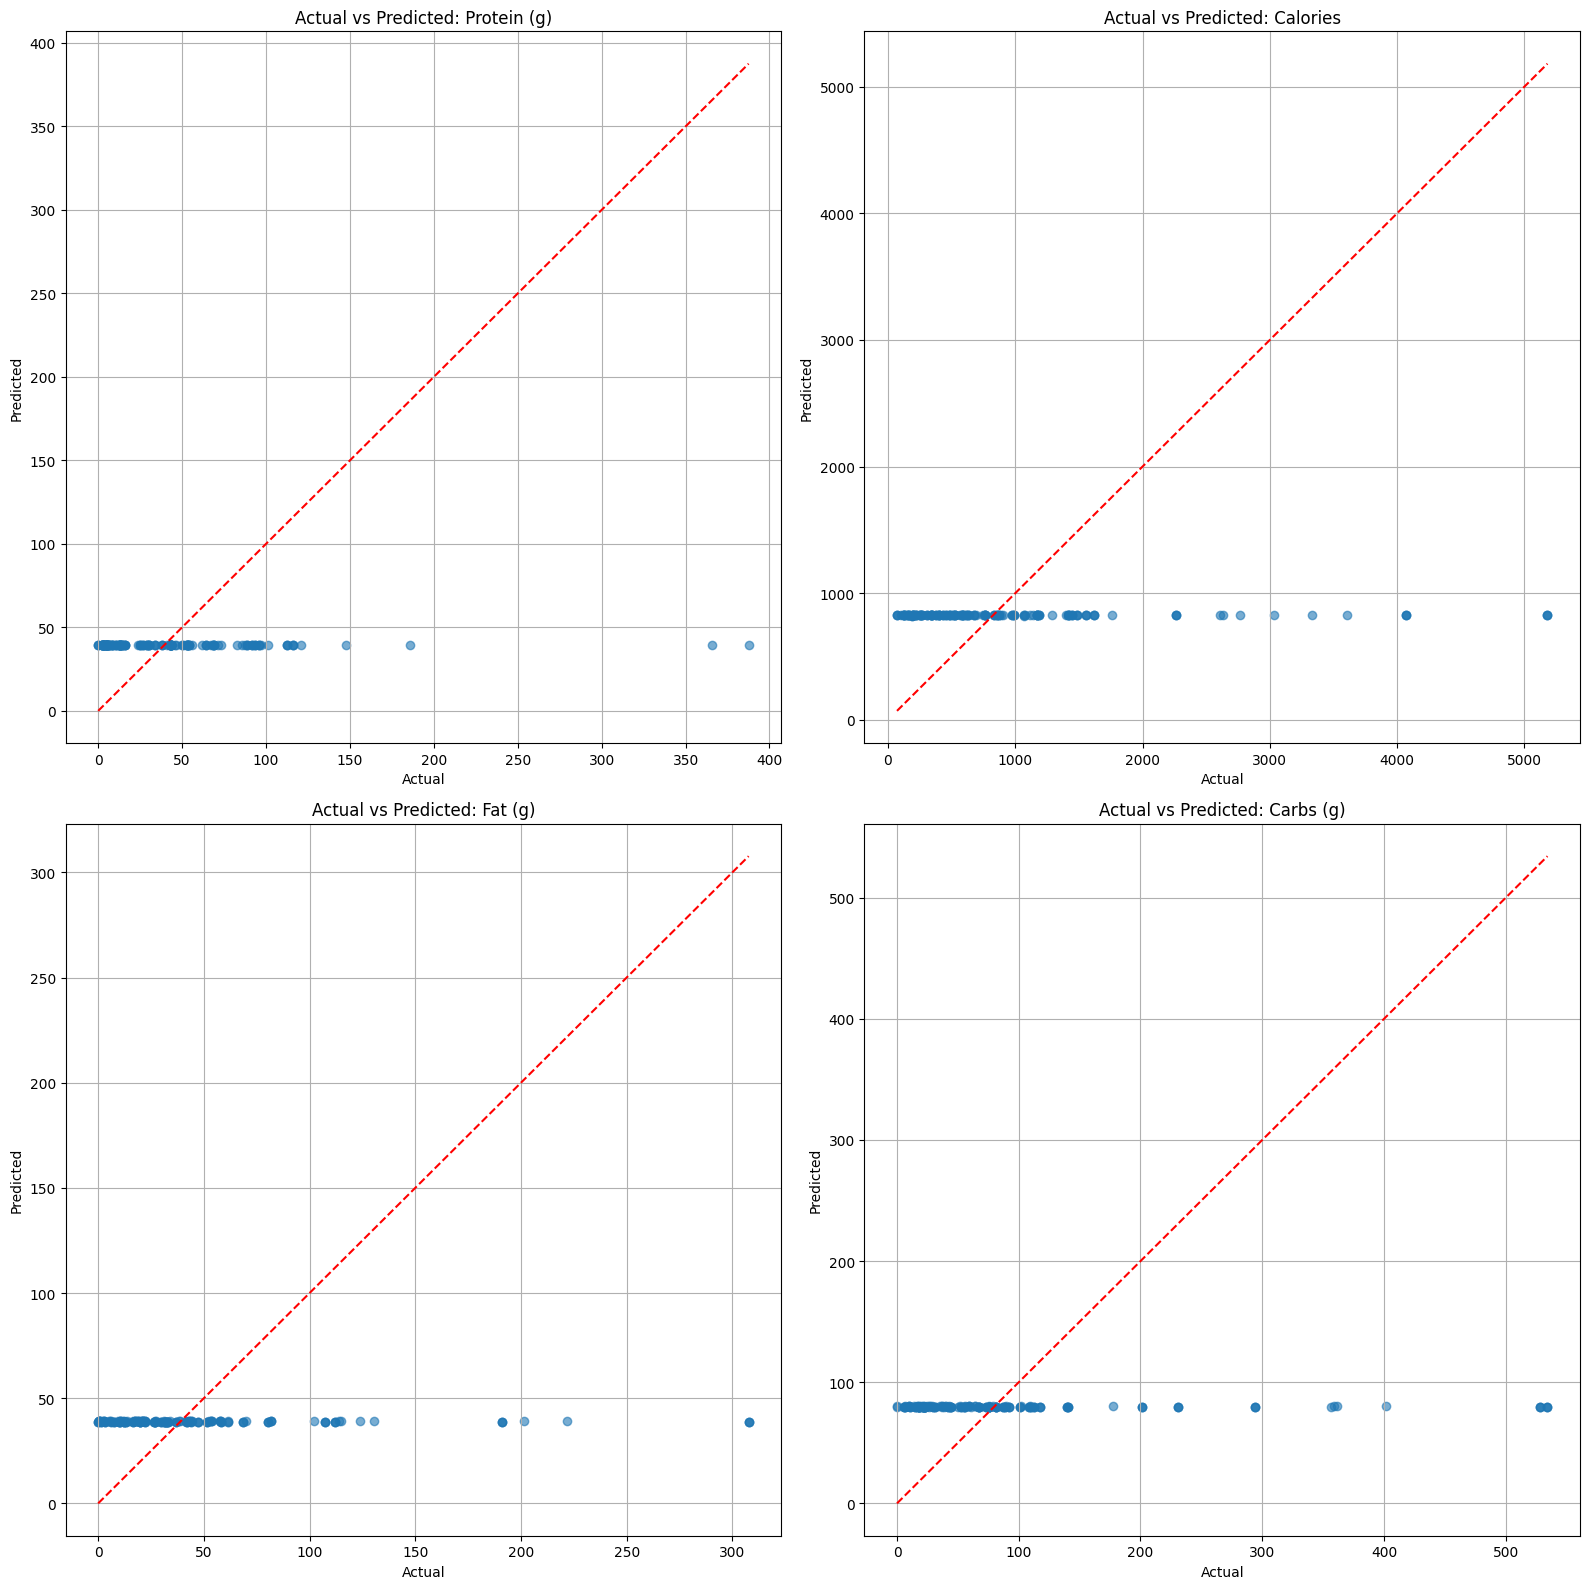

In [ ]:
y_true  = test_labels
y_pred_eff = efficientnet_model.predict(test_ds)

nutrients = ['Protein (g)', 'Calories', 'Fat (g)', 'Carbs (g)']

plt.figure(figsize=(16, 16))

for i in range(4):
    plt.subplot(2, 2, i+1)
    plt.scatter(y_true[:, i], y_pred_eff[:, i], alpha=0.6)

    #  y = x
    min_v = min(y_true[:, i].min(), y_pred_eff[:, i].min())
    max_v = max(y_true[:, i].max(), y_pred_eff[:, i].max())
    plt.plot([min_v, max_v], [min_v, max_v], 'r--')

    plt.title(f"Actual vs Predicted: {nutrients[i]}")
    plt.xlabel("Actual")
    plt.ylabel("Predicted")
    plt.grid(True)

plt.tight_layout()
plt.show()




> **Model 3**



In [ ]:
import tensorflow as tf
from tensorflow.keras.applications import ResNet50V2
from tensorflow.keras import layers, models

resnet_base = ResNet50V2(
    include_top=False,
    weights='imagenet',
    input_shape=(224, 224, 3)
)

resnet_base.trainable = False

inputs = tf.keras.Input(shape=(224, 224, 3))
x = resnet_base(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(256, activation='relu')(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(4, name="nutri_outputs")(x)

resnet_model = tf.keras.Model(inputs, outputs)

# 3)  compile  (Regression → MSE + MAE)
resnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss='mse',
    metrics=['mae']
)

resnet_model.summary()


94668760/94668760 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50v2 (Functional)         │ (None, 7, 7, 2048)     │    23,564,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ nutri_outputs (Dense)           │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,090,372 (91.90 MB)

 Trainable params: 525,572 (2.00 MB)

 Non-trainable params: 23,564,800 (89.89 MB)

In [ ]:
history_resnet = resnet_model.fit(
    train_ds,
    validation_data=test_ds,
    epochs=30
)


Epoch 1/30
42/42 ━━━━━━━━━━━━━━━━━━━━ 160s 3s/step - loss: 286958.0625 - mae: 214.7778 - val_loss: 292324.1250 - val_mae: 189.2001
Epoch 2/30
42/42 ━━━━━━━━━━━━━━━━━━━━ 136s 3s/step - loss: 175795.6406 - mae: 163.9203 - val_loss: 227478.1719 - val_mae: 180.4518
Epoch 3/30
42/42 ━━━━━━━━━━━━━━━━━━━━ 131s 3s/step - loss: 146479.9531 - mae: 162.4921 - val_loss: 221956.9844 - val_mae: 180.4465
Epoch 4/30
42/42 ━━━━━━━━━━━━━━━━━━━━ 133s 3s/step - loss: 137676.7812 - mae: 159.0421 - val_loss: 220689.6406 - val_mae: 178.7696
Epoch 5/30
42/42 ━━━━━━━━━━━━━━━━━━━━ 153s 3s/step - loss: 137834.9375 - mae: 160.1679 - val_loss: 217008.3281 - val_mae: 178.2128
Epoch 6/30
42/42 ━━━━━━━━━━━━━━━━━━━━ 146s 3s/step - loss: 173400.3125 - mae: 178.6007 - val_loss: 216103.0000 - val_mae: 173.8205
Epoch 7/30
42/42 ━━━━━━━━━━━━━━━━━━━━ 144s 3s/step - loss: 161955.2031 - mae: 168.3850 - val_loss: 212666.3750 - val_mae: 174.6357
Epoch 8/30
42/42 ━━━━━━━━━━━━━━━━━━━━ 142s 3s/step - loss: 138978.6875 - mae: 156.9

In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_pred_res = resnet_model.predict(test_ds)

y_true = test_labels

metrics = {}

for i, col in enumerate(target_cols):
    mae  = mean_absolute_error(y_true[:, i], y_pred_res[:, i])
    mse  = mean_squared_error(y_true[:, i], y_pred_res[:, i])
    rmse = np.sqrt(mse)
    r2   = r2_score(y_true[:, i], y_pred_res[:, i])

    metrics[col] = {
        'MAE': mae,
        'MSE': mse,
        'RMSE': rmse,
        'R2': r2
    }

results_df = pd.DataFrame(metrics).T   #(rows = nutrients)
print("\nPer-target regression metrics (ResNet):")
print(results_df)



12/12 ━━━━━━━━━━━━━━━━━━━━ 32s 2s/step

Per-target regression metrics (ResNet):
                      MAE            MSE        RMSE        R2
protein_g       26.341885    2051.854980   45.297406  0.172638
calories_kcal  522.127869  776740.812500  881.329004  0.127446
fat_g           29.508219    2437.254395   49.368557  0.109236
carbs_g         62.982178   11488.712891  107.185414  0.034998


12/12 ━━━━━━━━━━━━━━━━━━━━ 28s 2s/step


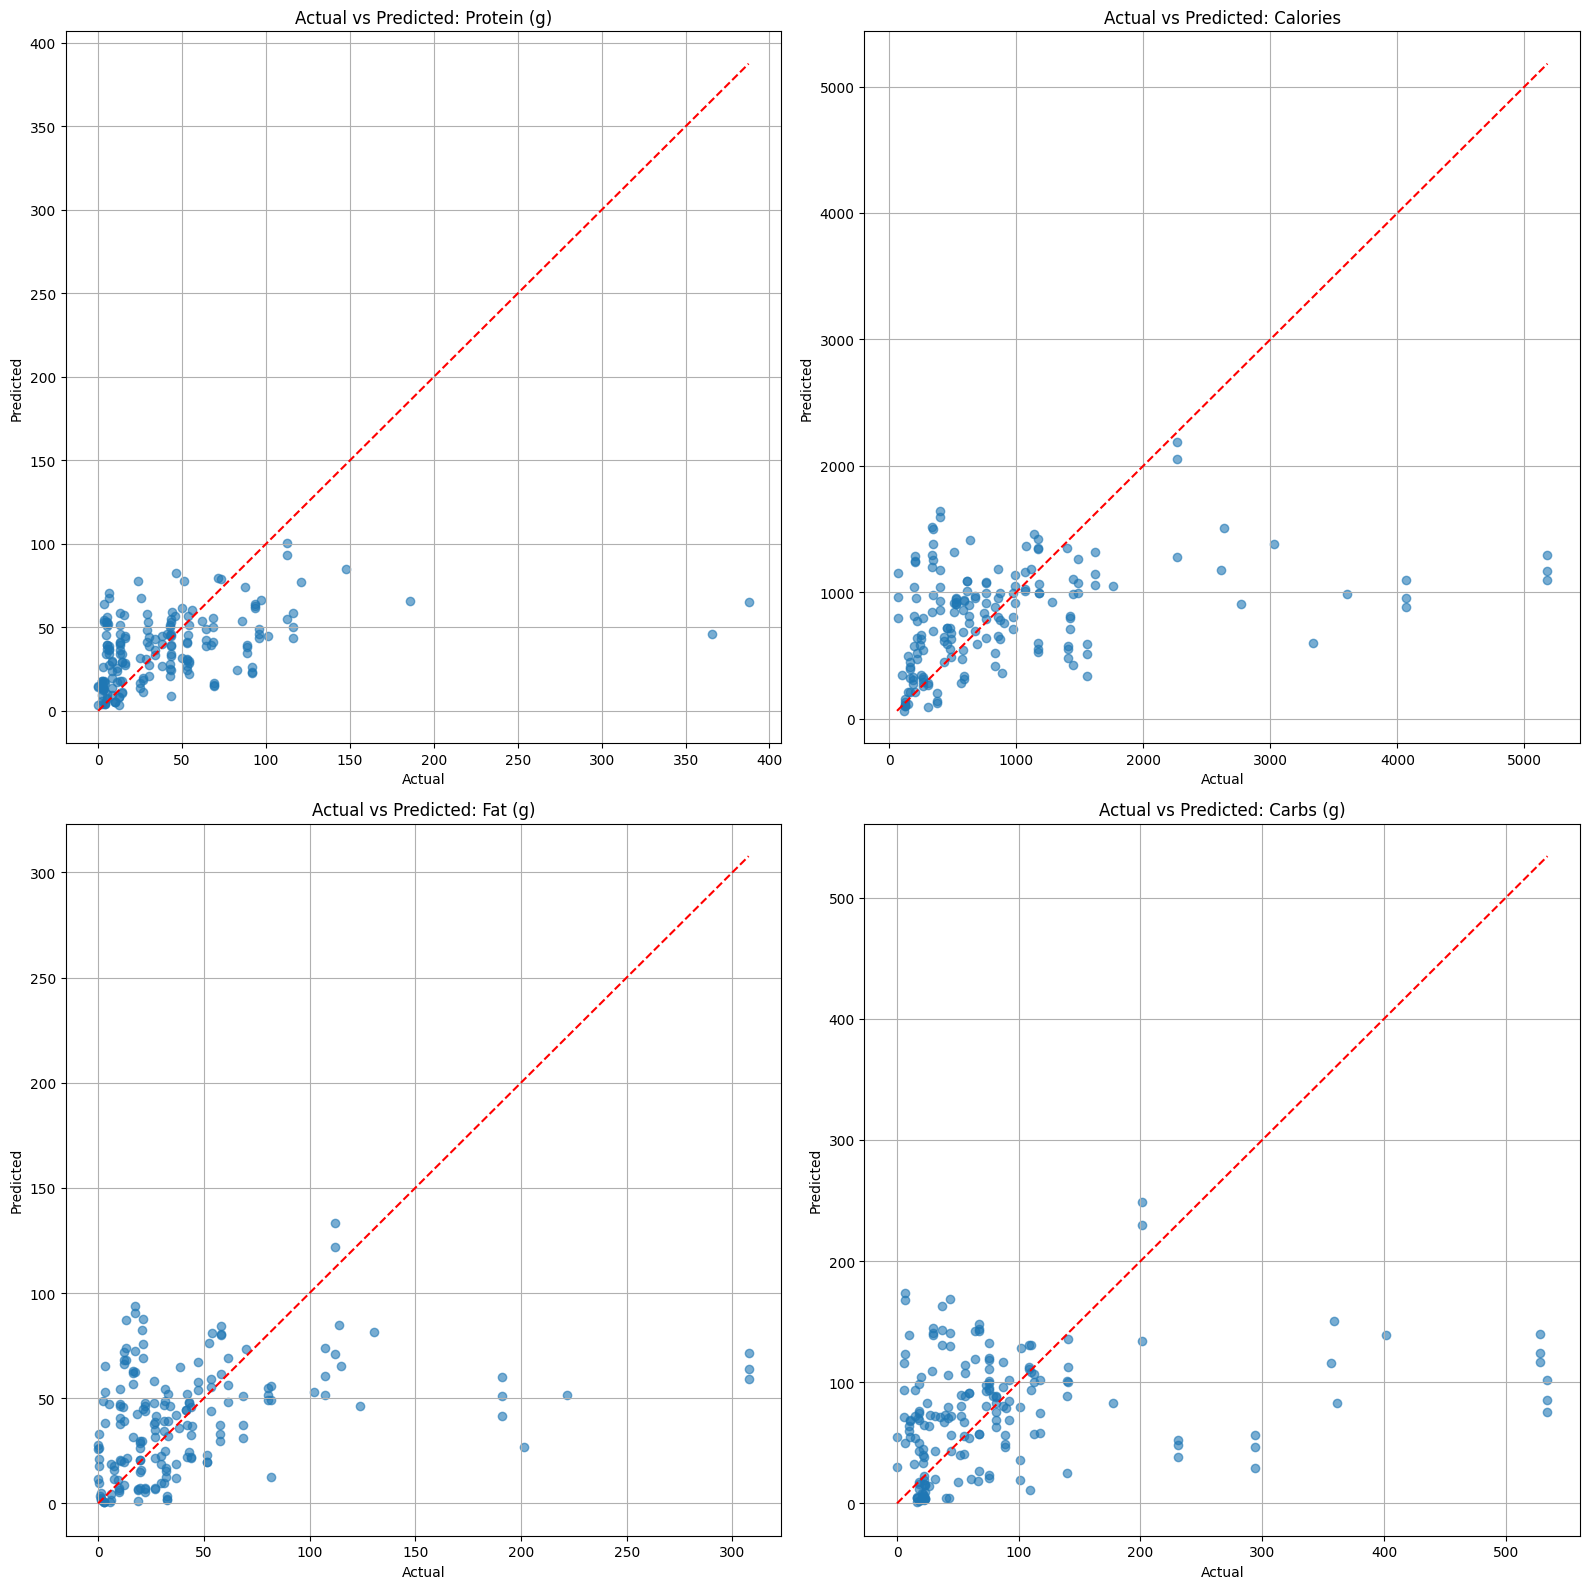

In [ ]:
import matplotlib.pyplot as plt
y_true  = test_labels
y_pred_res = resnet_model.predict(test_ds)

nutrients = ['Protein (g)', 'Calories', 'Fat (g)', 'Carbs (g)']

plt.figure(figsize=(16, 16))

for i in range(4):
    plt.subplot(2, 2, i+1)
    plt.scatter(y_true[:, i], y_pred_res[:, i], alpha=0.6)

    min_v = min(y_true[:, i].min(), y_pred_res[:, i].min())
    max_v = max(y_true[:, i].max(), y_pred_res[:, i].max())
    plt.plot([min_v, max_v], [min_v, max_v], 'r--')

    plt.title(f"Actual vs Predicted: {nutrients[i]}")
    plt.xlabel("Actual")
    plt.ylabel("Predicted")
    plt.grid(True)

plt.tight_layout()
plt.show()






> **Model Comparison**




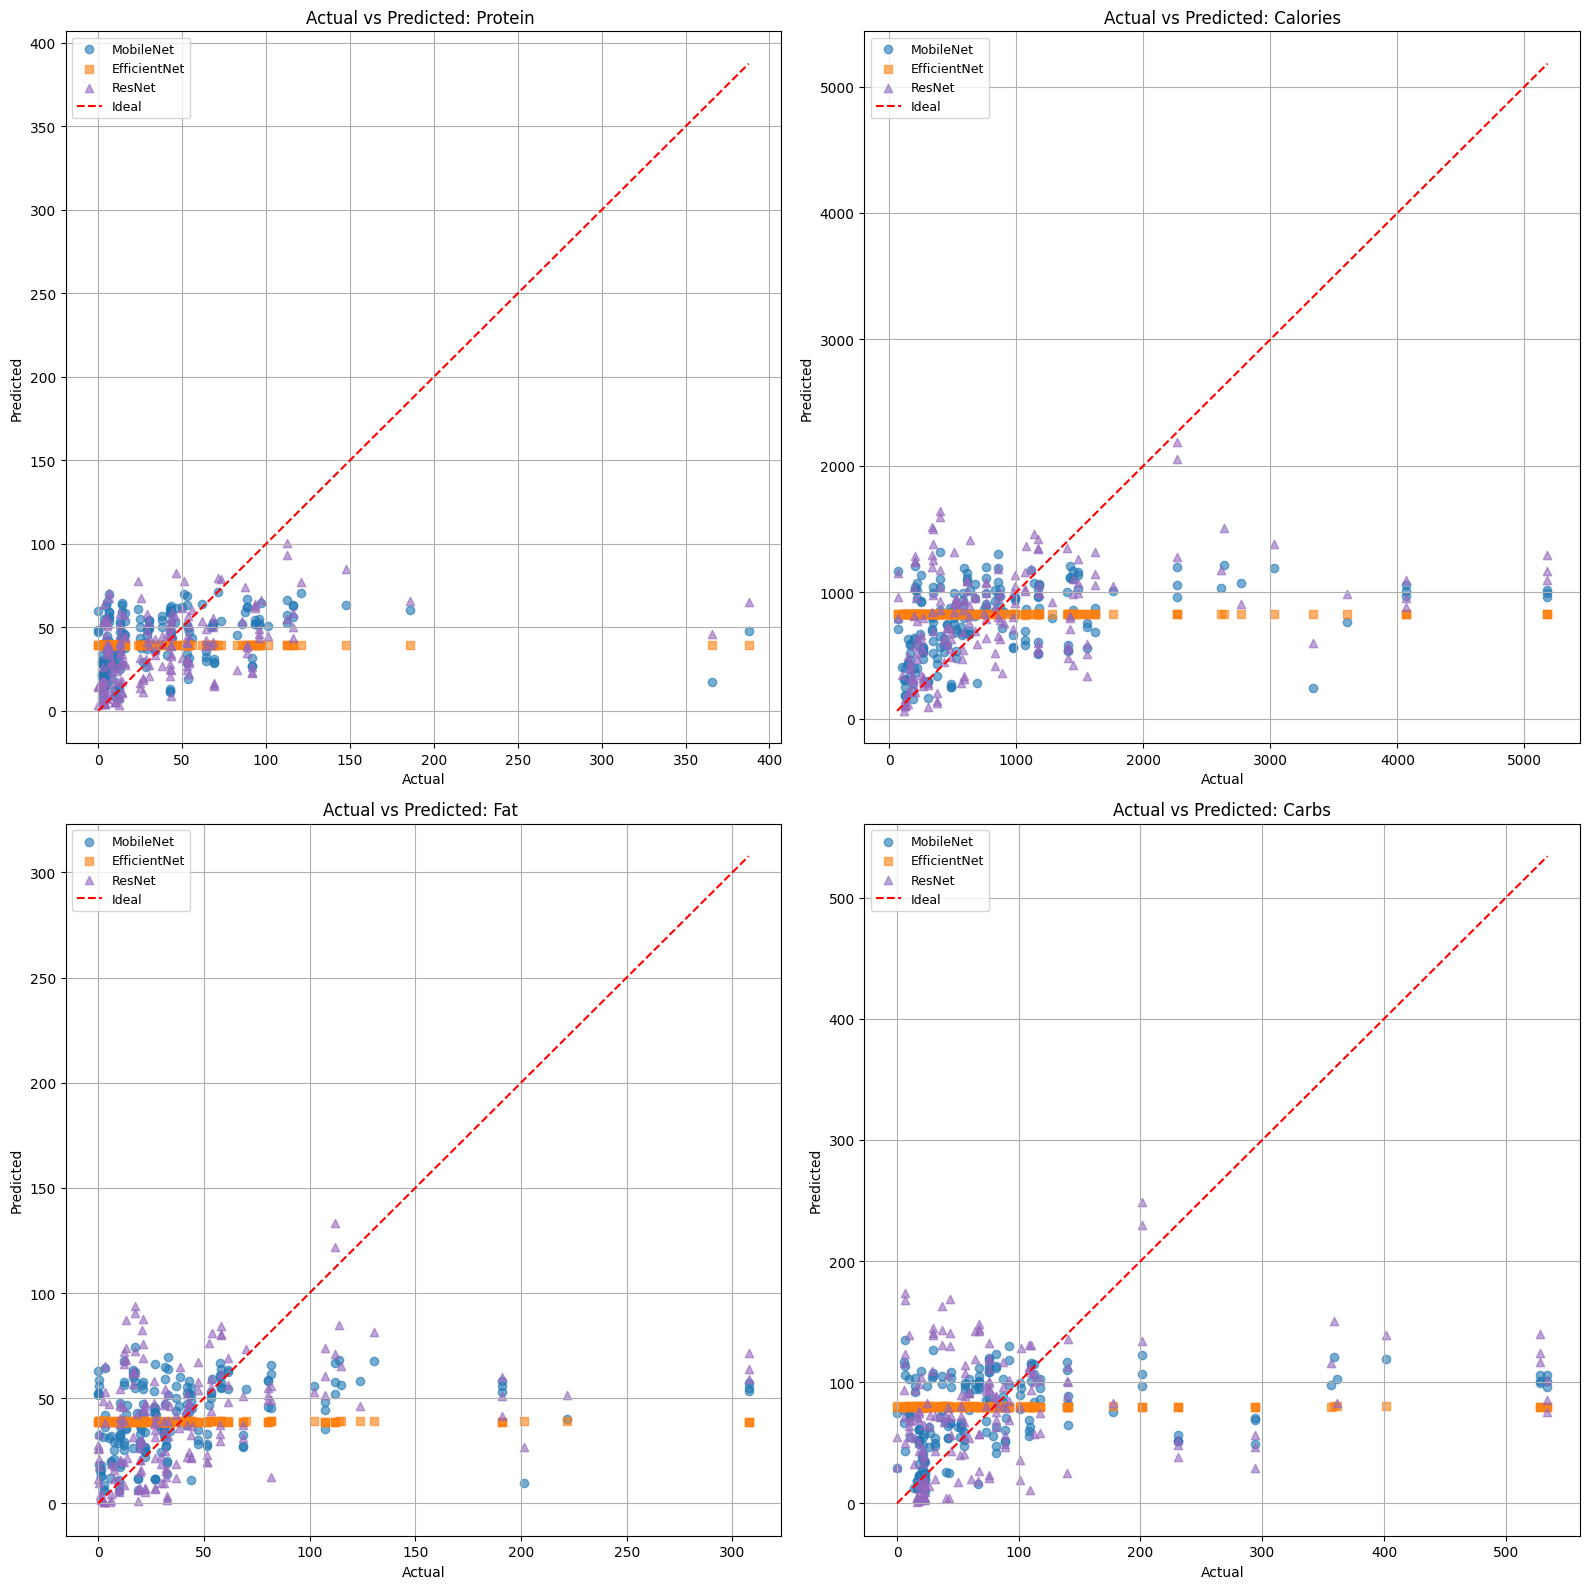

In [ ]:
import matplotlib.pyplot as plt

nutrients = ['Protein ', 'Calories', 'Fat ', 'Carbs']
plt.figure(figsize=(16, 16))

for i in range(4):
    plt.subplot(2, 2, i + 1)

    # MobileNet
    plt.scatter(
        y_true[:, i], y_pred_mobil[:, i],
        alpha=0.6, label='MobileNet', marker='o', color='tab:blue'
    )

    # EfficientNet
    plt.scatter(
        y_true[:, i], y_pred_eff[:, i],
        alpha=0.6, label='EfficientNet', marker='s', color='tab:orange'
    )

    # ResNet
    plt.scatter(
        y_true[:, i], y_pred_res[:, i],
        alpha=0.6, label='ResNet', marker='^', color='tab:purple'
    )

    min_v = min(
        y_true[:, i].min(),
        y_pred_mobil[:, i].min(),
        y_pred_eff[:, i].min(),
        y_pred_res[:, i].min()
    )
    max_v = max(
        y_true[:, i].max(),
        y_pred_mobil[:, i].max(),
        y_pred_eff[:, i].max(),
        y_pred_res[:, i].max()
    )

    plt.plot([min_v, max_v], [min_v, max_v], 'r--', label='Ideal')

    plt.title(f"Actual vs Predicted: {nutrients[i]}")
    plt.xlabel("Actual")
    plt.ylabel("Predicted")
    plt.grid(True)
    plt.legend(loc='upper left', fontsize=9)

plt.tight_layout()
plt.show()


In [ ]:

from sklearn.metrics import r2_score

def mean_r2_per_model(y_true, y_pred, target_cols):
    r2_list = []
    for i, col in enumerate(target_cols):
        r2 = r2_score(y_true[:, i], y_pred[:, i])
        r2_list.append(r2)
    return np.mean(r2_list)

#R2
mean_r2_mobil = mean_r2_per_model(y_true, y_pred_mobil, target_cols)
mean_r2_eff   = mean_r2_per_model(y_true, y_pred_eff,   target_cols)
mean_r2_res   = mean_r2_per_model(y_true, y_pred_res,   target_cols)


r2_table = pd.DataFrame({
    'Model': ['MobileNet', 'EfficientNe', 'ResNet'],
    'Mean R²': [mean_r2_mobil, mean_r2_eff, mean_r2_res]
})



print(r2_table)


         Model   Mean R²
0    MobileNet  0.084251
1  EfficientNe -0.003222
2       ResNet  0.111079




> **Model Comparison Summary**



Three deep-learning models were tested to predict nutritional values from food images: a custom mobilenet, EfficientNet, and ResNet.

EfficientNet: performed the worst with very high errors and near-zero or negative R² values, indicating that it failed to learn meaningful visual patterns.

Mobilenet: performed moderately with acceptable MAE values but still limited predictive power.

ResNet : achieved the best performance across most metrics, with the lowest MAE for protein and the highest R² values for calories, fat, and protein.

**Conclusion:**

ResNet is the most suitable model for our dataset, showing stronger feature extraction and more stable predictions compared to the other models.